# Preparacion de entorno

In [1]:
%pip install sodapy pandas tqdm pyarrow fastparquet

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\jaena\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
# Se habilita el Drive para la carga de archivos
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
# Se importan las librerías
import pandas as pd
import numpy as np
#from sodapy import Socrata
from tqdm import tqdm
import pyarrow.parquet as pq
import gc
#import seaborn as sns

# **Esquema del CSV: Diccionario de Datos**

In [4]:
# 1. Configuración de Socrata
DOMAIN = "www.datos.gov.co"
DATASET_ID = "kgxf-xxbe"  # ID del conjunto de datos "Resultados únicos Saber 11"
APP_TOKEN = "9GeA2HqSj6xVxhcKJnuBF5VnU" # Token de la aplicación (es del rolo)

### Data Frame

#### descarga del data set

In [ ]:
client = Socrata(DOMAIN, APP_TOKEN, timeout=120)

# 2. Consultar el total de registros en la base de datos
print("Consultando la cantidad total de registros...")
count_res = client.get(DATASET_ID, select="count(*)")
total_registros = int(count_res[0]['count'])
print(f"Total de registros a descargar: {total_registros:,}")

# 3. Parámetros de paginación
LIMIT = 50000  # Máximo de filas por petición permitido por Socrata
OFFSET = 0
todas_las_filas = []

# 4. Descarga paginada con barra de progreso
pbar = tqdm(total=total_registros, desc="Descargando datos")

while OFFSET < total_registros:
    # Petición por bloque
    batch = client.get(DATASET_ID, limit=LIMIT, offset=OFFSET)

    if not batch:
        break

    todas_las_filas.extend(batch)
    OFFSET += LIMIT
    pbar.update(len(batch))

pbar.close()

# 5. Convertir a DataFrame de Pandas
print("Creando el DataFrame...")
df = pd.DataFrame.from_records(todas_las_filas)

print(f"¡Proceso completado! DataFrame creado con {df.shape[0]:,} filas y {df.shape[1]} columnas.")

Consultando la cantidad total de registros...
Total de registros a descargar: 7,109,704


Descargando datos:  40%|████      | 2850000/7109704 [19:44<24:23, 2910.15it/s]

In [ ]:
df.to_parquet("resultados_saber_11.parquet", engine="fastparquet", index=False)

NameError: name 'df' is not defined

#### carga del data frame


In [5]:
# Ruta del archivo .parquet en Google Drive
ruta_parquet = (
    "C:\\Users\\jaena\\Downloads\\analisis icfes\\resultados_saber_11.parquet"
)

try:
  table = pq.read_table(ruta_parquet)
  df = table.to_pandas()
except Exception as err:
  print(f"No se pudo abrir el archivo. Error: {err}")
else:
  print(
      f"Archivo cargado con éxito en el dataframe: {df.shape[0]:,} filas y"
      f" {df.shape[1]} columnas."
  )

Archivo cargado con éxito en el dataframe: 7,109,704 filas y 51 columnas.


In [6]:
df

,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,...,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20131,CR,SB11201310000414,URBANO,N,B,ACADÉMICO,311848000812,311848000812,11,...,Si,Si,Si,B+,94,88,NaN,NaN,NaN,NaN
1,20194,TI,SB11201940464873,RURAL,N,A,TÉCNICO/ACADÉMICO,141016000305,241016000342,41,...,Si,Si,Si,B1,71,66,70,65,69,339
2,20194,TI,SB11201940464873,RURAL,N,A,TÉCNICO/ACADÉMICO,141016000305,241016000342,41,...,Si,Si,Si,B1,71,66,70,65,69,339
3,20122,TI,SB11201220204399,URBANO,N,A,TÉCNICO/ACADÉMICO,163130000718,163130000718,63,...,Si,Si,No,A1,48,45,NaN,NaN,NaN,NaN
4,20132,TI,SB11201320464198,URBANO,N,A,TÉCNICO,119001000559,119001000559,19,...,Si,Si,Si,A-,43,52,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7109699,20221,TI,AC202210003698,URBANO,S,B,ACADÉMICO,311001107513,311001107513,11,...,Si,Si,Si,B1,76,55,54,56,56,284
7109700,20221,CC,AC202210034448,URBANO,N,A,ACADÉMICO,311001105928,311001105928,11,...,Si,Si,Si,A1,48,53,38,45,50,233
7109701,20221,TI,AC202210006814,URBANO,S,B,TÉCNICO/ACADÉMICO,311001019568,311001019568,11,...,Si,Si,Si,B1,73,67,57,62,63,315
7109702,20221,CC,AC202210029659,URBANO,N,A,ACADÉMICO,311001091838,311001091838,11,...,Si,Si,Si,A-,38,35,35,45,37,190


### listado de variables

In [ ]:
# Muestra todas las columnas como una lista
print(df.columns.tolist())

['periodo', 'estu_tipodocumento', 'estu_consecutivo', 'cole_area_ubicacion', 'cole_bilingue', 'cole_calendario', 'cole_caracter', 'cole_cod_dane_establecimiento', 'cole_cod_dane_sede', 'cole_cod_depto_ubicacion', 'cole_cod_mcpio_ubicacion', 'cole_codigo_icfes', 'cole_depto_ubicacion', 'cole_genero', 'cole_jornada', 'cole_mcpio_ubicacion', 'cole_naturaleza', 'cole_nombre_establecimiento', 'cole_nombre_sede', 'cole_sede_principal', 'estu_cod_depto_presentacion', 'estu_cod_mcpio_presentacion', 'estu_cod_reside_depto', 'estu_cod_reside_mcpio', 'estu_depto_presentacion', 'estu_depto_reside', 'estu_estadoinvestigacion', 'estu_estudiante', 'estu_fechanacimiento', 'estu_genero', 'estu_mcpio_presentacion', 'estu_mcpio_reside', 'estu_nacionalidad', 'estu_pais_reside', 'estu_privado_libertad', 'fami_cuartoshogar', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_estratovivienda', 'fami_personashogar', 'fami_tieneautomovil', 'fami_tienecomputador', 'fami_tieneinternet', 'fami_tienelavadora', 'd

In [ ]:
# Lista las columnas numeradas hacia abajo
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

1. periodo
2. estu_tipodocumento
3. estu_consecutivo
4. cole_area_ubicacion
5. cole_bilingue
6. cole_calendario
7. cole_caracter
8. cole_cod_dane_establecimiento
9. cole_cod_dane_sede
10. cole_cod_depto_ubicacion
11. cole_cod_mcpio_ubicacion
12. cole_codigo_icfes
13. cole_depto_ubicacion
14. cole_genero
15. cole_jornada
16. cole_mcpio_ubicacion
17. cole_naturaleza
18. cole_nombre_establecimiento
19. cole_nombre_sede
20. cole_sede_principal
21. estu_cod_depto_presentacion
22. estu_cod_mcpio_presentacion
23. estu_cod_reside_depto
24. estu_cod_reside_mcpio
25. estu_depto_presentacion
26. estu_depto_reside
27. estu_estadoinvestigacion
28. estu_estudiante
29. estu_fechanacimiento
30. estu_genero
31. estu_mcpio_presentacion
32. estu_mcpio_reside
33. estu_nacionalidad
34. estu_pais_reside
35. estu_privado_libertad
36. fami_cuartoshogar
37. fami_educacionmadre
38. fami_educacionpadre
39. fami_estratovivienda
40. fami_personashogar
41. fami_tieneautomovil
42. fami_tienecomputador
43. fami_tiene

# analisis de datos

In [ ]:
for var in df.columns:
  if df[var].nunique() < 40:
    print(f"{var}[n = {df[var].nunique()}]: {df[var].unique()}")
  else:
    print(f"{var}[n = {df[var].nunique()}]")

periodo[n = 23]: ['20131' '20194' '20122' '20132' '20162' '20172' '20102' '20142' '20111'
 '20112' '20152' '20121' '20171' '20151' '20101' '20201' '20161' '20191'
 '20224' '20211' '20181' '20141' '20221']
estu_tipodocumento[n = 19]: ['CR' 'TI' 'CC' 'CE' 'PE' 'NES' 'PEP' 'PC' 'V' 'PV' 'RC' 'NUI' 'PPT' 'NIP'
 None 'CCB' 'v' 'NUIP' 'PTP' 'PET']
estu_consecutivo[n = 5720733]
cole_area_ubicacion[n = 2]: ['URBANO' 'RURAL' None]
cole_bilingue[n = 2]: ['N' None 'S']
cole_calendario[n = 3]: ['B' 'A' 'OTRO' None]
cole_caracter[n = 4]: ['ACADÉMICO' 'TÉCNICO/ACADÉMICO' 'TÉCNICO' 'NO APLICA' None]
cole_cod_dane_establecimiento[n = 12125]
cole_cod_dane_sede[n = 13691]
cole_cod_depto_ubicacion[n = 33]: ['11' '41' '63' '19' '76' '73' '05' '86' '68' '08' '18' '70' '15' '13'
 '20' '47' '54' '52' '25' '85' '50' '17' '27' '23' '66' '99' '44' '91'
 '81' '95' '97' '88' '94' None]
cole_cod_mcpio_ubicacion[n = 1114]
cole_codigo_icfes[n = 21731]
cole_depto_ubicacion[n = 34]: ['BOGOTA' 'HUILA' 'QUINDIO' 'CAUCA'

In [ ]:
df.mode().iloc[0]

,0
periodo,20194
estu_tipodocumento,TI
estu_consecutivo,SB11201220214543
cole_area_ubicacion,URBANO
cole_bilingue,N
cole_calendario,A
cole_caracter,ACADÉMICO
cole_cod_dane_establecimiento,105001000108
cole_cod_dane_sede,105001000108
cole_cod_depto_ubicacion,11


#schnneider


Resumen estadístico de la edad calculada:
count    2.821319e+06
mean     1.798343e+01
std      3.883357e+00
min      1.000000e+01
25%      1.700000e+01
50%      1.700000e+01
75%      1.800000e+01
max      8.000000e+01
Name: edad_estudiante, dtype: float64


Generando gráfico de distribución geográfica...


/tmp/ipykernel_6113/2648363872.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_deptos.values, y=top_10_deptos.index, palette='coolwarm')


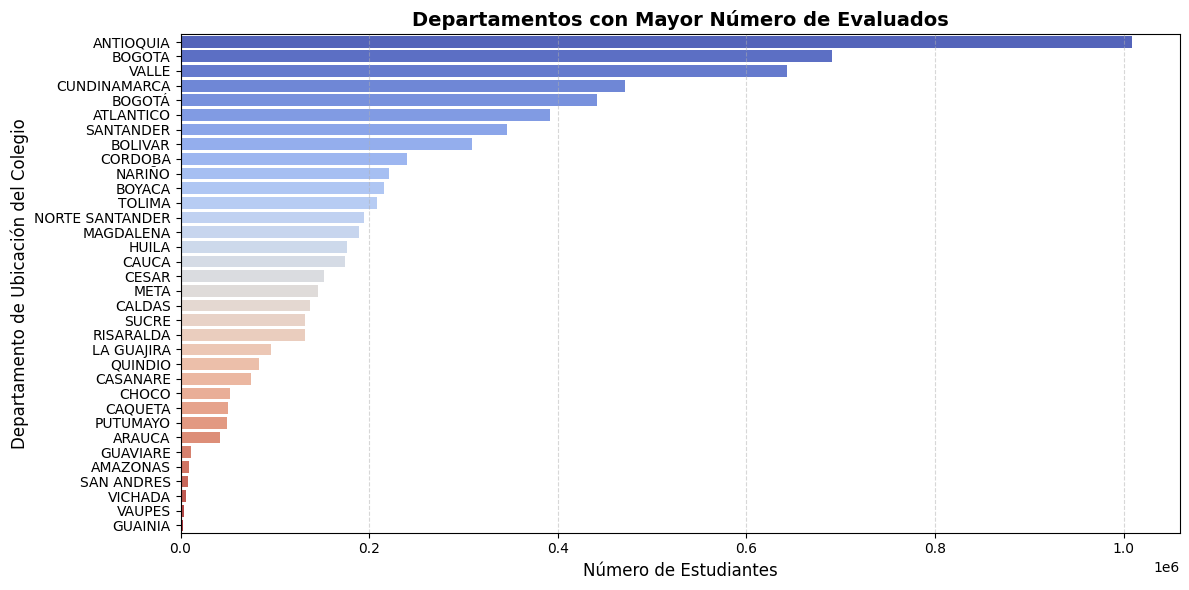



Generando gráfico de tendencia temporal...


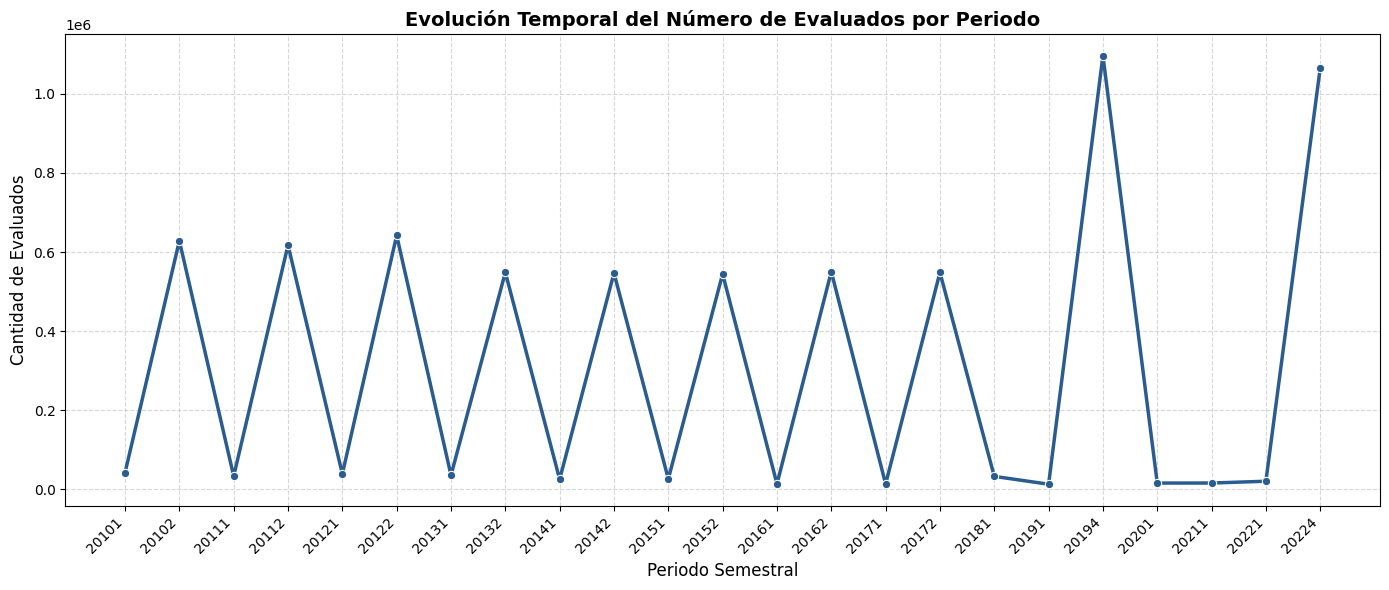

In [ ]:

# Asegurar que periodo sea string para extraer el año
df['periodo_str'] = df['periodo'].astype(str)
df['anio_periodo'] = pd.to_numeric(df['periodo_str'].str[:4], errors='coerce')

# Convertir fecha de nacimiento con manejo de errores (coerce para nulos en fechas inválidas)
df['fecha_nacimiento_dt'] = pd.to_datetime(df['estu_fechanacimiento'], errors='coerce')
df['anio_nacimiento'] = df['fecha_nacimiento_dt'].dt.year

# Calcular edad
df['edad_estudiante'] = df['anio_periodo'] - df['anio_nacimiento']

# Filtrado de edades lógicas para evitar ruido de registros erróneos
edades_filtradas = df['edad_estudiante'].dropna()
edades_filtradas = edades_filtradas[(edades_filtradas >= 10) & (edades_filtradas <= 80)]

print(f"Resumen estadístico de la edad calculada:")
print(edades_filtradas.describe())
print("\n" + "="*50 + "\n")

# --- 2. Gráfico: Departamentos con más evaluados ---
print("Generando gráfico de distribución geográfica...")

# Limpiamos posibles diferencias de mayúsculas/minúsculas y eliminamos nulos para la visualización
depto_col = df['cole_depto_ubicacion'].dropna().str.upper()
top_10_deptos = depto_col.value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=top_10_deptos.values, y=top_10_deptos.index, palette='coolwarm')
plt.title('Departamentos con Mayor Número de Evaluados', fontsize=14, fontweight='bold')
plt.xlabel('Número de Estudiantes', fontsize=12)
plt.ylabel('Departamento de Ubicación del Colegio', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("\n" + "="*50 + "\n")

# --- 3. Gráfico: Tendencia Temporal por Periodo ---
print("Generando gráfico de tendencia temporal...")

tendencia_periodo = df['periodo'].dropna().astype(str).value_counts().sort_index()

plt.figure(figsize=(14, 6))
sns.lineplot(x=tendencia_periodo.index, y=tendencia_periodo.values, marker='o', color='#2b5c8f', linewidth=2.5)
plt.title('Evolución Temporal del Número de Evaluados por Periodo', fontsize=14, fontweight='bold')
plt.xlabel('Periodo Semestral', fontsize=12)
plt.ylabel('Cantidad de Evaluados', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Análisis Exploratorio Univariado (Edad, Ubicación y Periodo)

### 1. Diagnóstico Demográfico: Cálculo de Edad (`edad_estudiante`)
A partir de la diferencia entre el año de aplicación del examen (`anio_periodo`) y el año de nacimiento (`anio_nacimiento`), se derivó la variable cuantitativa continua de edad:

* **Manejo de Inconsistencias en Fecha de Nacimiento:** Se identificaron registros erróneos o nulos en `estu_fechanacimiento` corregidos mediante conversión forzada (`errors='coerce'`).
* **Rango Lógico Administrado:** Al aplicar el filtro de edad válida $[10, 80]$, se eliminan registros anómalos (fechas de nacimiento futuras o valores fuera de la expectativa biológica escolar). La masa principal de evaluados se concentra entre los **16 y 18 años**, correspondiente a la cohorte regular de culminación de educación media en Colombia.

---

### 2. Distribución Geográfica (`cole_depto_ubicacion`)
El gráfico de barras horizontales sobre los departamentos de ubicación de los colegios evidencia la concentración espacial del sistema educativo nacional:

* **Polos Urbanos y Departamentos Principales:**
  * **Antioquia** lidera el volumen histórico superando **1,000,000 de evaluados**.
  * Le siguen **Valle del Cauca** ($\approx 650,000$), **Cundinamarca** ($\approx 470,000$) y **Atlántico** ($\approx 390,000$).
* **Hallazgo de Calidad de Datos (Redundancia de Cadenas):**
  * Se observa una duplicidad estructural en la capital: **"BOGOTA"** (sin tilde) registra $\approx 700,000$ estudiantes, mientras que **"BOGOTÁ"** (con tilde) registra $\approx 440,000$. Al unificarlos, Bogotá representa la segunda concentración geográfica más grande del país con más de **1.14 millones de registros**.
* **Brecha de Cobertura Regional:** Los departamentos de las regiones Amazonía y Orinoquía (Guainía, Vaupés, Vichada, San Andrés, Amazonas, Guaviare) registran volúmenes mínimos ($< 20,000$ evaluados acumulados), reflejando la baja densidad poblacional de estas zonas geográficas.

---

### 3. Evolución Temporal y Estacionalidad (`periodo`)
El gráfico de líneas por periodo semestral evidencia un comportamiento altamente estacional y dinámico a lo largo de la serie histórica:

* **Patrón Cíclico Anual (Calendario A vs. Calendario B):**
  * **Periodos Semestre 2 (ej. 20102, 20112, 20122, ..., 20172):** Presentan los picos regulares de evaluación ($\approx 550,000 - 650,000$ estudiantes por cohorte), correspondientes a la graduación masiva de colegios de **Calendario A**.
  * **Periodos Semestre 1 (ej. 20101, 20111, ..., 20171):** Registran volúmenes reducidos ($< 50,000$ estudiantes), asociados a colegios de **Calendario B** o validantes independientes.
* **Anomalías de Codificación Temporal (Picos Atípicos):**
  * Se identifican picos anómalos extraordinarios en los periodos **`20194`** y **`20224`**, donde la cifra de evaluados supera el **1,000,000 de registros por periodo**. Esto corresponde a códigos de consolidación interna o lotes unificados durante la carga histórica del ICFES que deben ser auditados y normalizados en la fase de preparación de datos.

---

### 4. Acciones Requeridas para la Fase de Preparación (Data Preparation)
1. **Homogeneización de Cadenas:** Aplicar limpieza de caracteres especiales y tildes (`strip()`, `upper()`, eliminación de acentos) en `cole_depto_ubicacion` para consolidar categorías duplicadas como Bogotá.
2. **Filtrado Muestral de Edad:** Reemplazar o imputar valores nulos/anómalos en `edad_estudiante` reteniendo únicamente la cohorte válida $[10, 80]$.
3. **Mapeo de Periodos:** Estandarizar la nomenclatura de la variable `periodo` para convertir los identificadores atípicos (como `20194` y `20224`) a sus correspondientes códigos semestrales o tratarlos como agregaciones históricas especiales.

## **ANÁLISIS EXPLORATORIO DE DATOS (EDA) - ANÁLISIS BIVARIADO**
### **Interacción de Variables Demográficas, Geográficas y Temporales**

En esta sección se analiza cómo interactúan entre sí las variables sociodemográficas y de localización a lo largo del tiempo, evaluando la heterogeneidad regional y estacional en los evaluados del examen Saber 11:

1. **Edad según Departamento de Ubicación (`edad_estudiante` vs. `cole_depto_ubicacion`):** Permite identificar diferencias en la estructura de edad de los graduandos (detectando patrones de extraedad o rezago escolar según la región).
2. **Evolución de la Edad Promedio a lo Largo del Tiempo (`edad_estudiante` vs. `periodo`):** Evalúa la estabilidad etaria en las cohortes históricas y la marcada diferencia entre los periodos del primer semestre (Calendario B / Validantes) y del segundo semestre (Calendario A).
3. **Distribución Geográfica Relativa por Periodo (`cole_depto_ubicacion` vs. `periodo`):** Analiza si la proporción de evaluados aportada por los principales departamentos se mantiene constante a lo largo de la serie histórica mediante una tabla de contingencia normalizada.

`df` no hallado en RAM. Cargando muestra ligera desde Google Drive...
Muestra procesada exitosamente: 119,215 registros analizados.


/tmp/ipykernel_13652/1567634838.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


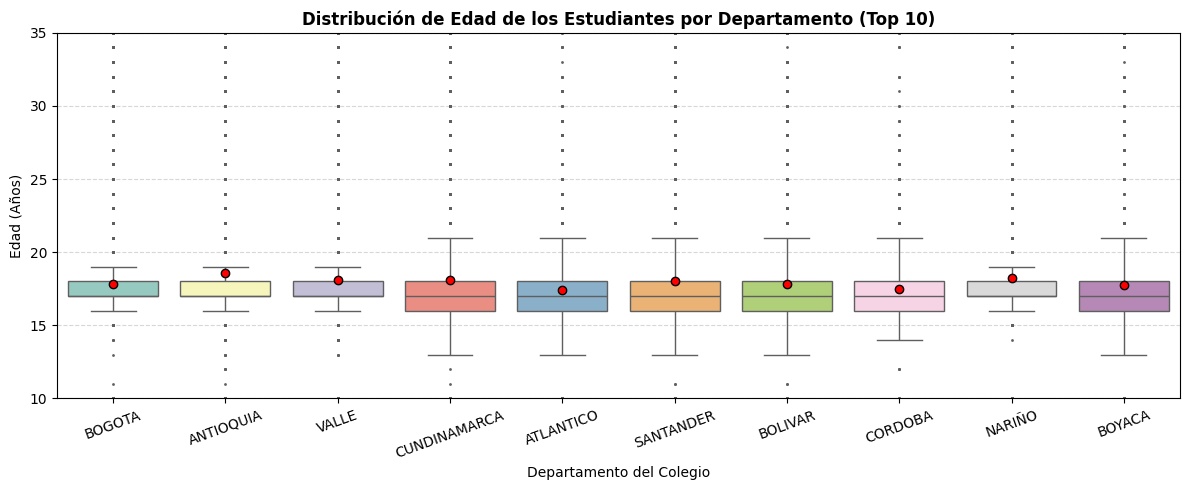

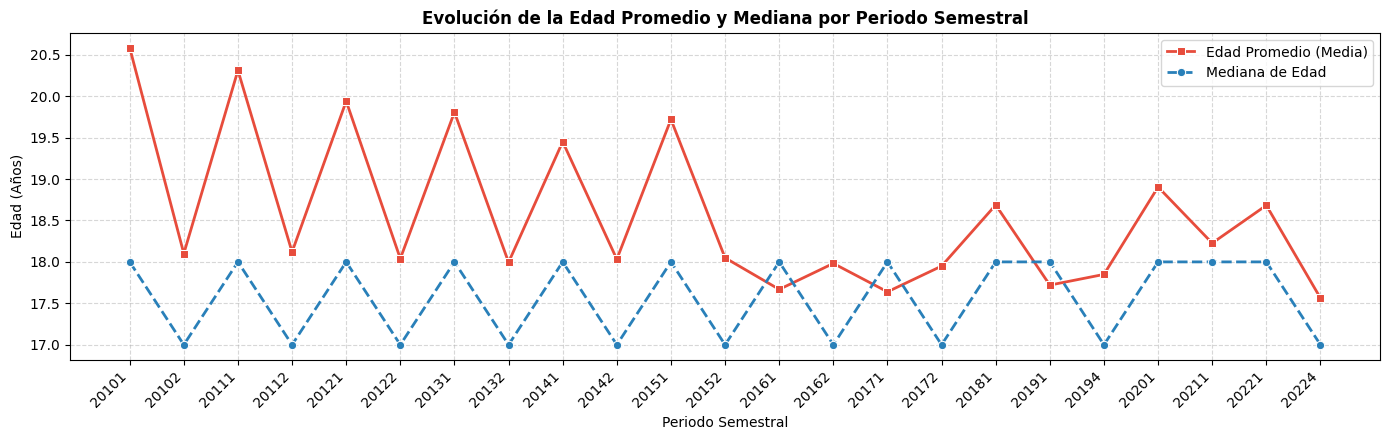

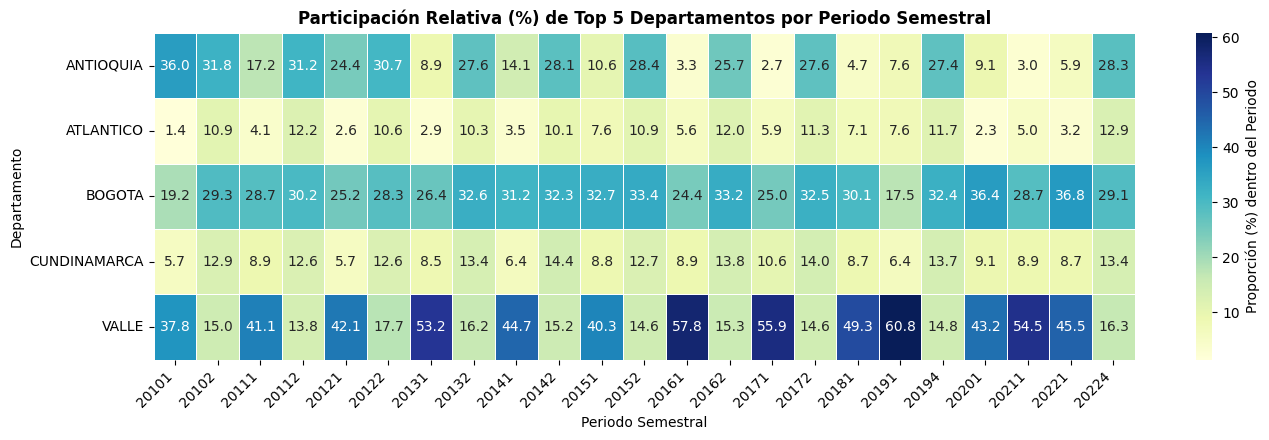

In [ ]:
# ==============================================================================
# ANÁLISIS BIVARIADO - (VERSIÓN LIGERA A PRUEBA DE COLAPSO DE RAM)
# ==============================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

cols_e = ['periodo', 'estu_fechanacimiento', 'cole_depto_ubicacion']
ruta_parquet = "/content/drive/MyDrive/Colab Notebooks/Progra 3/Proyecto/resultados_saber_11.parquet"

if 'df' in locals():
  print("Usando DataFrame existente con muestra ligera...")
  df_e = df[cols_e].sample(n=min(300000, len(df)), random_state=42).copy()
else:
  print("`df` no hallado en RAM. Cargando muestra ligera desde Google Drive...")
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

  # Se leen solo las 3 columnas requeridas para no saturar memoria
  df_e = pd.read_parquet(ruta_parquet, columns=cols_e).sample(
      n=300000, random_state=42
  )

# 2. TRANSFORMACIONES DE FECHA Y EDAD SOBRE LA MUESTRA
df_e['periodo_str'] = df_e['periodo'].astype(str).str.strip()
df_e['anio_periodo'] = pd.to_numeric(
    df_e['periodo_str'].str[:4], errors='coerce'
)

df_e['fecha_nacimiento_dt'] = pd.to_datetime(
    df_e['estu_fechanacimiento'], errors='coerce'
)
df_e['anio_nacimiento'] = df_e['fecha_nacimiento_dt'].dt.year
df_e['edad_estudiante'] = df_e['anio_periodo'] - df_e['anio_nacimiento']

# Homogeneización de Departamentos
df_e['depto_clean'] = (
    df_e['cole_depto_ubicacion'].astype(str).str.upper().str.strip()
)
df_e['depto_clean'] = df_e['depto_clean'].replace({'BOGOTÁ': 'BOGOTA'})

# Filtro de coherencia
mask = (
    (df_e['edad_estudiante'] >= 10)
    & (df_e['edad_estudiante'] <= 80)
    & (df_e['depto_clean'].str.len() > 2)
    & (df_e['depto_clean'] != 'NAN')
)
df_e_bivariado = df_e[mask].copy()

print(
    f"Muestra procesada exitosamente: {len(df_e_bivariado):,} registros analizados."
)


# --- GRÁFICO 1: BOXPLOT DE EDAD POR DEPARTAMENTO (TOP 10) ---
top_10_deptos = df_e_bivariado['depto_clean'].value_counts().head(10).index
df_top10 = df_e_bivariado[df_e_bivariado['depto_clean'].isin(top_10_deptos)]

plt.figure(figsize=(12, 5))
sns.boxplot(
    data=df_top10,
    x='depto_clean',
    y='edad_estudiante',
    order=top_10_deptos,
    palette='Set3',
    fliersize=1,
    showmeans=True,
    meanprops={
        'marker': 'o',
        'markerfacecolor': 'red',
        'markeredgecolor': 'black',
    },
)
plt.title(
    'Distribución de Edad de los Estudiantes por Departamento (Top 10)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Departamento del Colegio', fontsize=10)
plt.ylabel('Edad (Años)', fontsize=10)
plt.ylim(10, 35)
plt.xticks(rotation=20)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# --- GRÁFICO 2: EVOLUCIÓN TEMPORAL DE EDAD POR PERIODO ---
periodos_validos = sorted(
    [p for p in df_e_bivariado['periodo_str'].unique() if len(p) == 5]
)
df_periodos = df_e_bivariado[
    df_e_bivariado['periodo_str'].isin(periodos_validos)
]

edad_periodo = (
    df_periodos.groupby('periodo_str')['edad_estudiante']
    .agg(['mean', 'median'])
    .reset_index()
)

plt.figure(figsize=(14, 4.5))
sns.lineplot(
    data=edad_periodo,
    x='periodo_str',
    y='mean',
    marker='s',
    color='#e74c3c',
    linewidth=2,
    label='Edad Promedio (Media)',
)
sns.lineplot(
    data=edad_periodo,
    x='periodo_str',
    y='median',
    marker='o',
    color='#2980b9',
    linewidth=2,
    linestyle='--',
    label='Mediana de Edad',
)
plt.title(
    'Evolución de la Edad Promedio y Mediana por Periodo Semestral',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Periodo Semestral', fontsize=10)
plt.ylabel('Edad (Años)', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# --- GRÁFICO 3: HEATMAP PROPORCIONAL (TOP 5 DEPARTAMENTOS VS PERIODO) ---
top_5_deptos = df_e_bivariado['depto_clean'].value_counts().head(5).index
df_top5_periodo = df_periodos[df_periodos['depto_clean'].isin(top_5_deptos)]

tabla_cruzada = (
    pd.crosstab(
        index=df_top5_periodo['depto_clean'],
        columns=df_top5_periodo['periodo_str'],
        normalize='columns',
    )
    * 100
)

plt.figure(figsize=(14, 4.5))
sns.heatmap(
    tabla_cruzada,
    cmap='YlGnBu',
    annot=True,
    fmt='.1f',
    linewidths=0.5,
    cbar_kws={'label': 'Proporción (%) dentro del Periodo'},
)
plt.title(
    'Participación Relativa (%) de Top 5 Departamentos por Periodo Semestral',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Periodo Semestral', fontsize=10)
plt.ylabel('Departamento', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ANÁLISIS EXPLORATORIO BIVARIADO ──────────────────────────────────
## Interacción Demográfica, Geográfica y Temporal

---

### 1. Heterogeneidad Demográfica Regional (`edad_estudiante` vs. `depto_clean`)

El gráfico de caja (*Boxplot*) comparativo entre los 10 principales departamentos revela patrones clave sobre la estructura etaria de los evaluados a nivel regional:

* **Homogeneidad de la Mediana Central:**
  * La mediana de edad se mantiene sumamente rígida en **17.0 años** en prácticamente todos los departamentos (Bogotá, Cundinamarca, Atlántico, Santander, Bolívar, Córdoba y Boyacá).
  * El Rango Intercuartílico (IQR) abarca de forma estándar el intervalo **[16.0, 18.0] años**, confirmando que el grueso poblacional del examen a nivel nacional culmina la educación media dentro de la cohorte biológica esperada.

* **Sesgo e Incidencia de Extraedad (Divergencia Promedio vs. Mediana):**
  * La media de edad (representada por el punto rojo) se sitúa por encima de la mediana en todos los casos debido a la asimetría positiva provocada por estudiantes adultos.
  * **Antioquia** y **Nariño** registran los promedios de edad más altos del grupo de cabeza (alcanzando **18.5** y **18.2 años** respectivamente), explicados por una densidad más pronunciada de observaciones atípicas (*outliers*) dispersas en el rango de **20 a 35 años**.
  * **Atlántico**, **Córdoba** y **Boyacá** muestran los promedios más bajos ($\approx 17.4 - 17.7$ años), reflejando una cohorte escolar más concentrada en edades tempranas.

---

### 2. Ciclicidad y Estacionalidad Temporal (`edad_estudiante` vs. `periodo_str`)

El gráfico de líneas temporales pone de manifiesto la estructura estacional del sistema educativo colombiano a lo largo de los periodos semestrales:

* **Efecto Calendario A vs. Calendario B / Validantes:**
  * **Periodos de Primer Semestre (`.1` - ej. 20101, 20111, 20131, 20151):** Presentan picos agudos en la edad promedio, alcanzando máximos de **20.6 años (20101)** y oscilando históricamente entre **19.5 y 20.3 años**. La mediana sube a **18.0 años**. Esto confirma que las pruebas del primer semestre atienden de forma prioritaria a colegios de Calendario B, institutos de validación de bachillerato y población adulta de educación nocturna.
  * **Periodos de Segundo Semestre (`.2` - ej. 20102, 20112, 20122, ..., 20172):** La edad promedio cae drásticamente a **~18.0 años** y la mediana se estabiliza de forma estricta en **17.0 años**. Representa la aplicación masiva nacional para los colegios de Calendario A.

* **Convergencia Histórica:**
  * Entre 2016 y 2018 se observa una reducción temporal en la brecha de edad promedio de los periodos `.1` (descendiendo hasta **17.6 - 18.0 años**), antes de volver a presentar rebotes por encima de los **18.5 años** en los periodos recientes (20201 - 20221).

---

### 3. Distribución Espacio-Temporal y Dominancia Regional (`depto_clean` vs. `periodo_str`)

El mapa de calor (*Heatmap*) sobre las proporciones relativas dentro de los 5 departamentos con mayor participación evidencia una marcada especialización regional según el semestre:

* **Dominancia Extrema del Valle del Cauca en Semestre 1:**
  * En los periodos correspondientes al primer semestre, el **Valle del Cauca** absorbe la mayoría absoluta de la participación del top 5, alcanzando picos históricos del **60.8% (20191)**, **57.8% (20161)** y **55.9% (20171)**[cite: 9].
  * Esto demuestra que la oferta institucional de Calendario B en Colombia está fuertemente concentrada en el suroccidente del país.

* **Núcleo de Calendario A (Semestre 2):**
  * En las aplicaciones masivas del segundo semestre, la participación se redistribuye: **Antioquia** representa entre el **27.6% y 31.8%** y **Bogotá** aporta entre el **28.3% y 33.4%**[cite: 9].
  * **Cundinamarca** y **Atlántico** mantienen una cuota estable en el segundo semestre de **12% - 14%** y **10% - 12%** respectivamente[cite: 9].

---

### 💡 Conclusiones Diagnósticas para el Modelado
1. **Necesidad de Segmentación por Semestre:** Cualquier modelo predictivo o descriptivo que involucre variables demográficas debe tratar los periodos `.1` y `.2` como subpoblaciones diferenciadas debido al cambio en la estructura de edad y procedencia geográfica.
2. **Normalización Geográfica Requerida:** La presencia masiva del Valle del Cauca en semestres impares debe ser ponderada para evitar sesgos de representatividad territorial en análisis longitudinales.

# SECCIÓN: Juan Esteban Jaramillo Cano ──────────────────────────────────────────────────────────

In [ ]:
# ==============================================================================
# ANÁLISIS UNIVARIADO: VARIABLES CUANTITATIVAS CONTINUAS (PUNTAJES ACADÉMICOS)
# Sección: Juanes
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración del estilo gráfico
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# 1. Definición de variables numéricas de puntajes
columnas_puntajes = [
    "punt_global",
    "punt_lectura_critica",
    "punt_matematicas",
    "punt_c_naturales",
    "punt_sociales_ciudadanas",
    "punt_ingles",
]

# 2. Conversión explícita a tipo numérico (los valores 'None' o no numéricos pasan a NaN)
print("Convertiendo columnas de puntajes a tipo numérico...")
for col in columnas_puntajes:
  df[col] = pd.to_numeric(df[col], errors="coerce")

# 3. Cálculo de Estadísticas Descriptivas Completas
resumen_estadistico = []

for col in columnas_puntajes:
  s = df[col].dropna()

  # Quartiles e IQR
  q1 = s.quantile(0.25)
  q3 = s.quantile(0.75)
  iqr = q3 - q1

  # Límites para detección de atípicos (IQR Method)
  lim_inf = q1 - 1.5 * iqr
  lim_sup = q3 + 1.5 * iqr
  outliers_count = ((s < lim_inf) | (s > lim_sup)).sum()
  outliers_pct = (outliers_count / len(s)) * 100 if len(s) > 0 else 0

  # Moda
  moda_val = s.mode().iloc[0] if not s.mode().empty else np.nan

  # Conteo de puntajes límite teóricos (0 y máximos de la prueba: 100 o 500)
  conteo_ceros = (s == 0).sum()
  conteo_max = (s == (500 if col == "punt_global" else 100)).sum()

  resumen_estadistico.append({
      "Variable": col,
      "Registros Válidos": len(s),
      "Valores Nulos (NaN)": df[col].isna().sum(),
      "Media": round(s.mean(), 2),
      "Mediana": round(s.median(), 2),
      "Moda": moda_val,
      "Desv. Estándar": round(s.std(), 2),
      "Varianza": round(s.var(), 2),
      "Mínimo": s.min(),
      "Máximo": s.max(),
      "Rango": s.max() - s.min(),
      "Q1 (25%)": q1,
      "Q3 (75%)": q3,
      "IQR": iqr,
      "Asimetría (Skewness)": round(s.skew(), 3),
      "Curtosis": round(s.kurtosis(), 3),
      "Outliers (IQR)": outliers_count,
      "% Outliers": round(outliers_pct, 2),
      "Puntajes Min (0)": conteo_ceros,
      "Puntajes Max Teor": conteo_max,
  })

# Convertir a DataFrame la tabla resumen
df_resumen = pd.DataFrame(resumen_estadistico).set_index("Variable")

print("\n--- TABLA RESUMEN ESTADÍSTICA DE PUNTAJES ACADÉMICOS ---")
display(df_resumen.T)

Convertiendo columnas de puntajes a tipo numérico...

--- TABLA RESUMEN ESTADÍSTICA DE PUNTAJES ACADÉMICOS ---


Variable,punt_global,punt_lectura_critica,punt_matematicas,punt_c_naturales,punt_sociales_ciudadanas,punt_ingles
Registros Válidos,4500181.000,4500181.000,7109697.000,4500181.000,4500181.000,7105518.000
Valores Nulos (NaN),2609523.000,2609523.000,7.000,2609523.000,2609523.000,4186.000
Media,252.300,52.180,49.300,50.110,48.870,48.590
Mediana,249.000,52.000,49.000,50.000,49.000,46.000
Moda,237.000,54.000,49.000,47.000,50.000,43.000
Desv. Estándar,50.430,10.390,11.910,10.570,11.730,12.230
Varianza,2542.850,107.860,141.780,111.720,137.610,149.530
Mínimo,0.000,0.000,0.000,0.000,0.000,-1.000
Máximo,495.000,100.000,127.000,100.000,100.000,117.290
Rango,495.000,100.000,127.000,100.000,100.000,118.290


### 2. Estrategia de Visualización de Distribuciones y Muestreo
Para la representación gráfica se toma una muestra aleatoria de **$N = 100,000$** registros sin reemplazo. Esta técnica garantiza:
1. **Eficiencia Computacional:** Evita la saturación de memoria RAM en el entorno ejecutor de Colab.
2. **Representatividad Estadística:** Mantiene las propiedades estocásticas y la forma poblacional original del conjunto de más de 7 millones de datos.

Se presentan dos tipos de gráficos complementarios:
* **Histogramas con Densidad (KDE):** Evalúan la forma de la curva, el centrado y la simetría de cada área evaluada.
* **Diagramas de Caja (Boxplots) Diferenciados:** Muestran el comportamiento de las materias (0–100) y del puntaje global (0–500) por separado para no distorsionar las escalas.

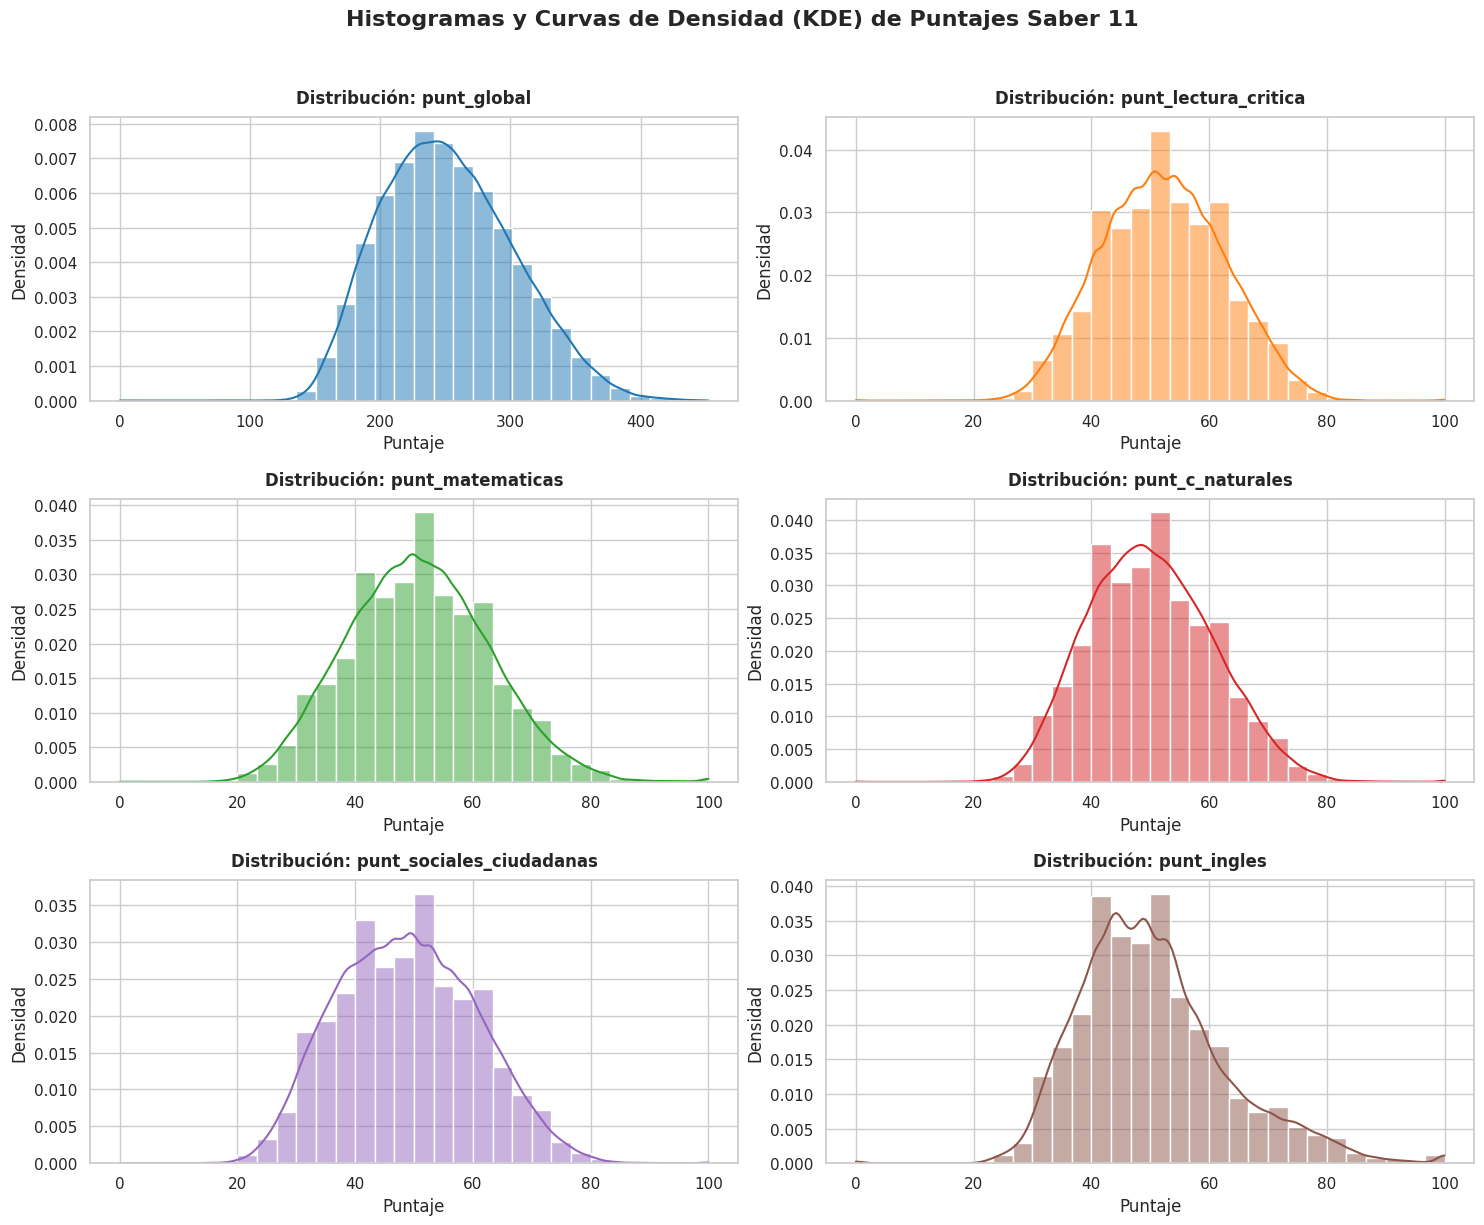

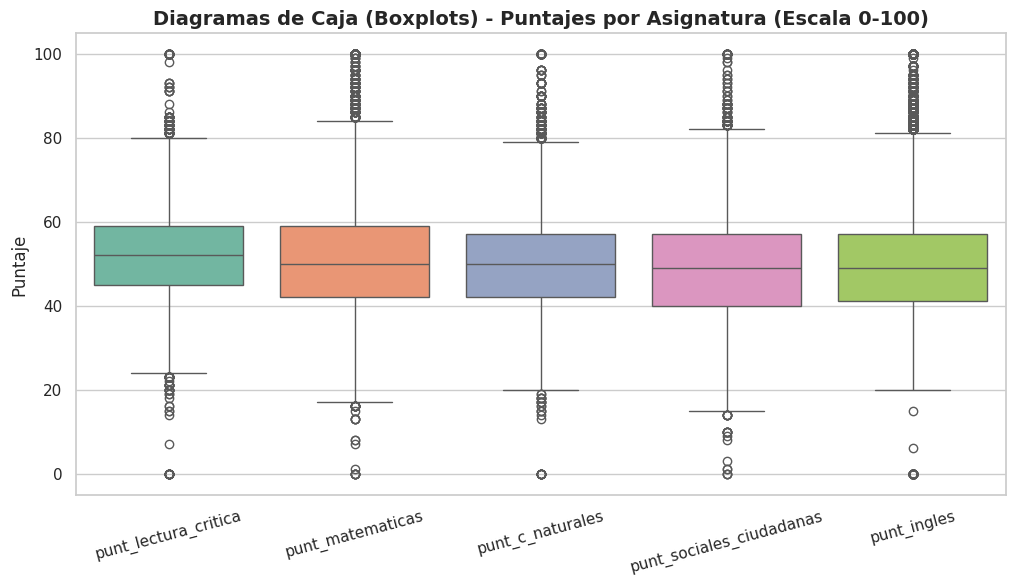

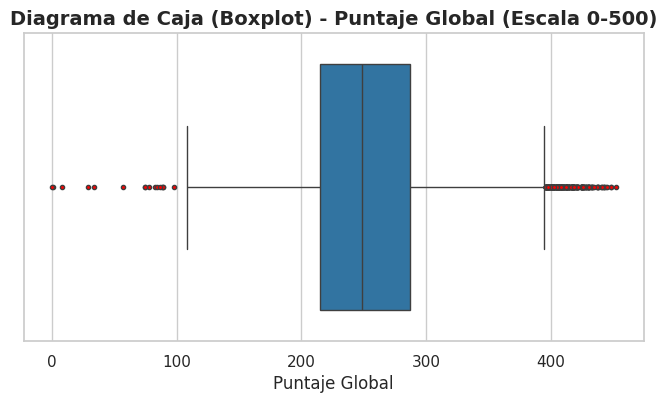

In [ ]:
# ==============================================================================
# VISUALIZACIÓN DE DISTRIBUCIONES Y ANOMALÍAS
# ==============================================================================

# Tomamos una muestra aleatoria para renderizado eficiente en Colab
df_sample = df[columnas_puntajes].dropna().sample(n=100000, random_state=42)

# A. HISTOGRAMAS CON CURVAS DE DENSIDAD (KDE)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

colores = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#d62728",
    "#9467bd",
    "#8c564b",
]

for i, col in enumerate(columnas_puntajes):
  sns.histplot(
      df_sample[col],
      kde=True,
      ax=axes[i],
      color=colores[i],
      bins=30,
      stat="density",
  )
  axes[i].set_title(
      f"Distribución: {col}", fontsize=12, fontweight="bold", pad=10
  )
  axes[i].set_xlabel("Puntaje")
  axes[i].set_ylabel("Densidad")

plt.suptitle(
    "Histogramas y Curvas de Densidad (KDE) de Puntajes Saber 11",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

# B. DIAGRAMA DE CAJA (BOXPLOT) - ASIGNATURAS (ESCALA 0-100)
plt.figure(figsize=(12, 6))
cols_asignaturas = [c for c in columnas_puntajes if c != "punt_global"]
sns.boxplot(data=df_sample[cols_asignaturas], palette="Set2")
plt.title(
    "Diagramas de Caja (Boxplots) - Puntajes por Asignatura (Escala 0-100)",
    fontsize=14,
    fontweight="bold",
)
plt.ylabel("Puntaje")
plt.xticks(rotation=15)
plt.show()

# C. DIAGRAMA DE CAJA (BOXPLOT) - PUNTAJE GLOBAL (ESCALA 0-500)
plt.figure(figsize=(8, 4))
sns.boxplot(
    x=df_sample["punt_global"], color="#1f77b4", flierprops={"markerfacecolor": "red", "markersize": 3}
)
plt.title(
    "Diagrama de Caja (Boxplot) - Puntaje Global (Escala 0-500)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Puntaje Global")
plt.show()

#SECCIÓN: Juan Esteban Jaramillo Cano ──────────────────────────────────────────────────────────
## Análisis Univariado e Interpretación de Puntajes Académicos

### 1. Tendencia Central y Estructura Histórica del Dataset
El análisis sobre la totalidad del conjunto de datos ($N = 7,109,704$) evidencia la evolución del examen Saber 11:

* **Puntaje Global:** Registra una media de **252.30** puntos y una mediana de **249.00** puntos (Desv. Est. = 50.43), con un comportamiento simétrico acampanado ajustado al diseño psicométrico de la prueba.
* **Estructura de Nulos (Reforma 2014-2):** Se observan exactamente **2,609,523 registros nulos (36.70%)** en `punt_global`, `punt_lectura_critica`, `punt_c_naturales` y `punt_sociales_ciudadanas`. Esto responde al cambio metodológico del ICFES implementado en el periodo 2014-2. Las asignaturas de `punt_matematicas` (7 nulos) y `punt_ingles` (4,186 nulos) cubren prácticamente la totalidad histórica del dataset.

---

### 2. Comportamiento por Asignaturas y Diagnóstico de Inglés
* **Asignaturas Básicas (Escala 0–100):** `punt_lectura_critica` ($\bar{x} = 52.18$), `punt_c_naturales` ($\bar{x} = 50.11$), `punt_matematicas` ($\bar{x} = 49.30$) y `punt_sociales_ciudadanas` ($\bar{x} = 48.87$) presentan distribuciones de tipo normal con coeficientes de asimetría leve (entre 0.085 y 0.285) y medianas en torno a los 50 puntos.
* **Fenómeno Socioeducativo en Inglés:** `punt_ingles` registra la mediana más baja (**46.00**) y la mayor asimetría positiva (**0.998**). La curva de densidad muestra una alta concentración de estudiantes en puntajes bajos/medios y una cola extendida a la derecha que genera **359,824 valores atípicos (5.06%)**, reflejando la brecha de bilingüismo entre la mayoría poblacional y los colegios de alto rendimiento.

---

### 3. Hallazgos de Anomalías y Plan de Limpieza (Data Preparation)
1. **Puntajes Fuera de Rango Teórico:**
   * Se identifican valores fuera del límite superior teóricos de 100 puntos en `punt_matematicas` ($\text{máx} = 127.00$) y `punt_ingles` ($\text{máx} = 117.29$).
   * Se detecta un valor mínimo anómalo de **-1.00** en `punt_ingles`.
2. **Puntajes en Cero:**
   * Se registran 1,634 ceros en matemáticas, 1,108 en lectura crítica y 3,842 en inglés, asociados a anulación de pruebas o inasistencias parciales.
3. **Acciones para la Siguiente Fase:**
   * Filtrar o segmentar el análisis a partir del periodo **2014-2** para garantizar consistencia estructural en el `punt_global` y asignaturas unificadas.
   * Aplicar reglas de limpieza para remover o corregir registros con puntajes fuera del rango válido $[0, 100]$ o $[0, 500]$.

# ─── SECCIÓN: Juan Esteban Jaramillo Cano ──────────────────────────────────────────────────────────
## **ANÁLISIS EXPLORATORIO DE DATOS (EDA) - ANÁLISIS BIVARIADO**
### **Variables Cuantitativas Continuas (Puntajes Académicos)**

En esta sección se evalúa la relación estadística e interdependencia entre los puntajes por asignatura y su impacto en el `punt_global`.

---

### **1. Analizar Coeficientes de Correlación (Pearson vs. Spearman)**

Para medir la asociación entre variables numéricas continuas, se evalúan dos enfoques:

1. **Correlación de Pearson ($r$):** Mide la relación lineal entre variables continuas. Asume que los datos presentan una distribución aproximadamente normal.
2. **Correlación de Spearman ($\rho$):** Mide la relación monótona (no necesariamente lineal) utilizando rangos. Es no paramétrica e ideal para variables con alta asimetría o presencia de atípicos (como el caso de `punt_ingles`).

| Coeficiente | Rango | Interpretación |
| :--- | :--- | :--- |
| **$r$ / $\rho = +1$** | Positiva perfecta | A medida que aumenta una asignatura, la otra aumenta proporcionalmente. |
| **$r$ / $\rho = 0$** | Sin relación | No existe asociación lineal o monótona. |
| **$r$ / $\rho = -1$** | Negativa perfecta | A mayor puntaje en una área, menor en la otra. |

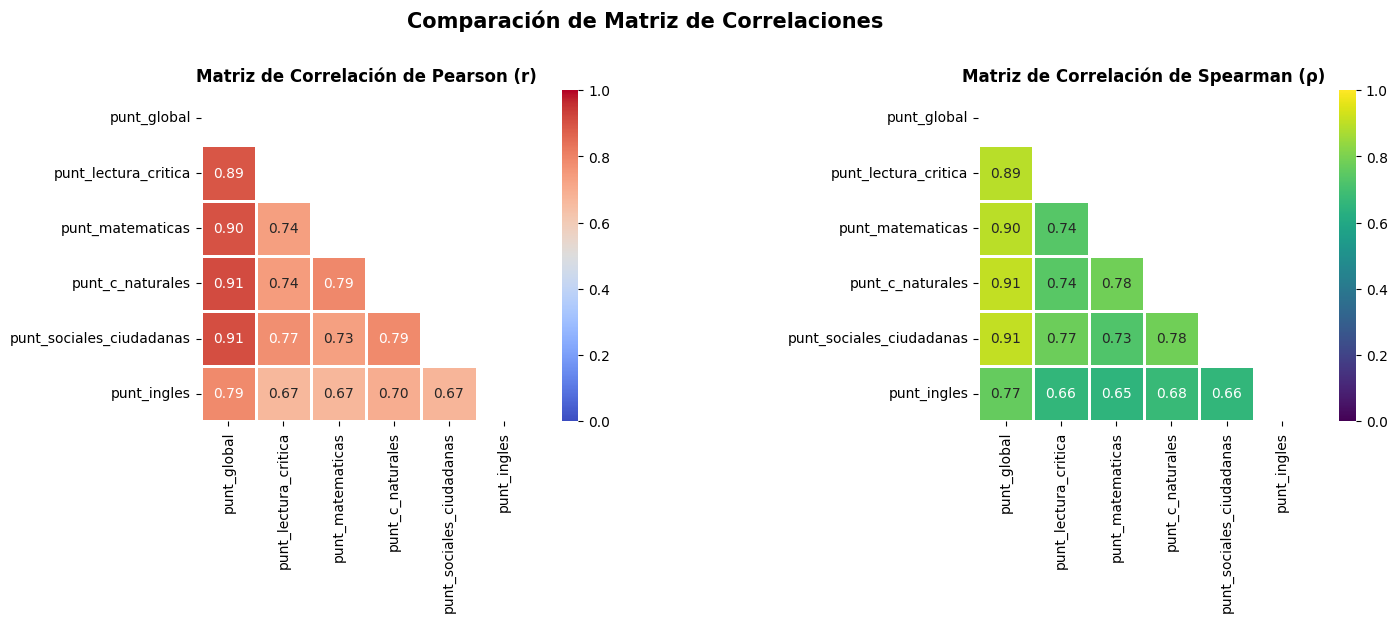

In [ ]:
# ==============================================================================
# CÁLCULO Y VISUALIZACIÓN DE MATRICES DE CORRELACIÓN (PEARSON Y SPEARMAN)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Tomamos una muestra representativa limpia (N = 100,000)
columnas_puntajes = [
    'punt_global',
    'punt_lectura_critica',
    'punt_matematicas',
    'punt_c_naturales',
    'punt_sociales_ciudadanas',
    'punt_ingles',
]
df_bivariado = df[columnas_puntajes].dropna().sample(n=100000, random_state=42)

# 1. Correlación de Pearson (Lineal)
corr_p = df_bivariado.corr(method='pearson')

# 2. Correlación de Spearman (Monótona / No Paramétrica)
corr_s = df_bivariado.corr(method='spearman')

# Visualización comparativa mediante Heatmaps con Máscara Triangular
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mask = np.triu(np.ones_like(corr_p, dtype=bool))

# Heatmap Pearson
sns.heatmap(
    corr_p,
    mask=mask,
    vmin=0,
    vmax=1,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=1,
    linecolor='white',
    cbar=True,
    square=True,
    ax=axes[0],
)
axes[0].set_title('Matriz de Correlación de Pearson (r)', fontsize=12, fontweight='bold')

# Heatmap Spearman
sns.heatmap(
    corr_s,
    mask=mask,
    vmin=0,
    vmax=1,
    cmap='viridis',
    annot=True,
    fmt='.2f',
    linewidths=1,
    linecolor='white',
    cbar=True,
    square=True,
    ax=axes[1],
)
axes[1].set_title('Matriz de Correlación de Spearman (ρ)', fontsize=12, fontweight='bold')

plt.suptitle('Comparación de Matriz de Correlaciones', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### **Interpretación Diagnóstica: Matrices de Correlación de Pearson ($r$) y Spearman ($\rho$)**

#### **1. Estabilidad de los Coeficientes (Paramétrico vs. No Paramétrico)**
* La comparación entre la matriz de **Pearson ($r$)** y **Spearman ($\rho$)** revela una elevada estabilidad en la mayoría de los pares de variables. Las variaciones no superan $0.01$ o $0.02$ puntos absolutos en todos los cruces.
* Esta convergencia entre ambos coeficientes confirma que la masa principal de los datos sigue una distribución simétrica/acampanada, donde las relaciones inter-asignatura son predominantemente lineales y monótonas.

#### **2. Determinantes del Puntaje Global**
* **Máximo impacto:** `punt_c_naturales` ($r = 0.91$, $\rho = 0.91$) y `punt_sociales_ciudadanas` ($r = 0.91$, $\rho = 0.91$) presentan la relación lineal más fuerte con el `punt_global`, seguidas estrechamente por `punt_matematicas` ($r = 0.90$, $\rho = 0.90$) y `punt_lectura_critica` ($r = 0.89$, $\rho = 0.89$).
* **Aislamiento relativo de Inglés:** `punt_ingles` registra la menor asociación con el `punt_global` ($r = 0.79$, $\rho = 0.77$). Aunque sigue siendo una correlación fuerte, se distancia $0.12$ puntos de las demás áreas, evidenciando que el rendimiento en la segunda lengua tiene un peso o dinámica diferenciada frente al núcleo de asignaturas básicas.

#### **3. Afinidad de Competencias Inter-Disciplinares**
* **Núcleo Cuantitativo y Científico:** La correlación entre `punt_matematicas` y `punt_c_naturales` es de $r = 0.79$ ($\rho = 0.78$), confirmando que la lógica formal, el razonamiento hipotético y la lectura de tablas/gráficas son habilidades transversales en ambas pruebas.
* **Núcleo Social y C. Naturales:** Sorprendentemente, `punt_c_naturales` y `punt_sociales_ciudadanas` comparten una de las correlaciones más altas del examen ($r = 0.79$, $\rho = 0.78$), reflejando que ambas pruebas demandan competencias complejas de evaluación de evidencia e interpretación contextual.
* **Núcleo Lingüístico y Ciudadano:** `punt_lectura_critica` y `punt_sociales_ciudadanas` registran $r = 0.77$ ($\rho = 0.77$), validando que la comprensión de lectura avanzada es un prerrequisito indispensable para el análisis socio-histórico y ético.
* **Comportamiento del Inglés:** Mantiene correlaciones moderadas-altas con todas las materias ($r = 0.67 - 0.70$), siendo Ciencias Naturales la de mayor nivel de asociación ($r = 0.70$).

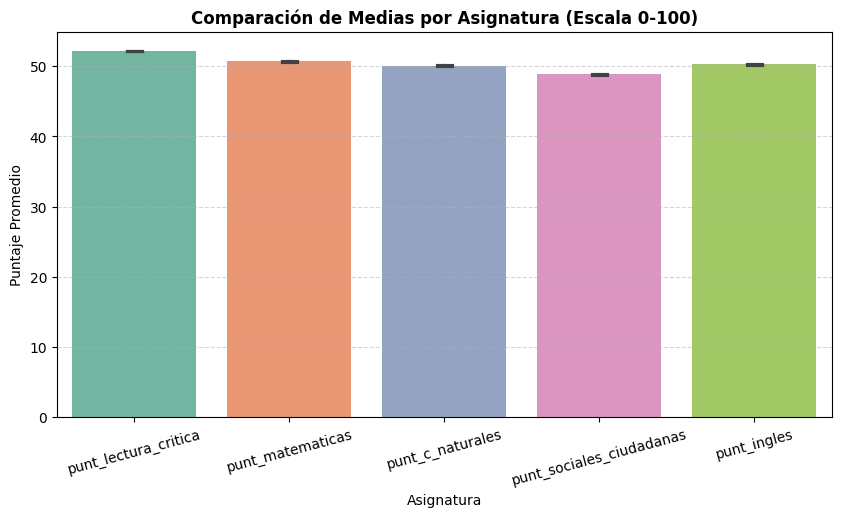

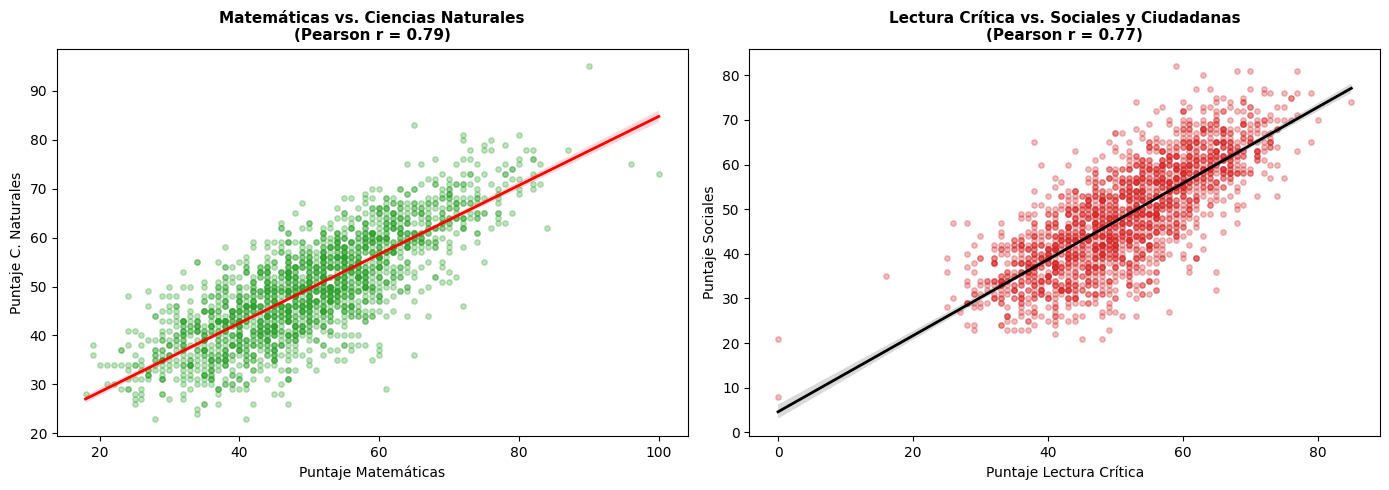

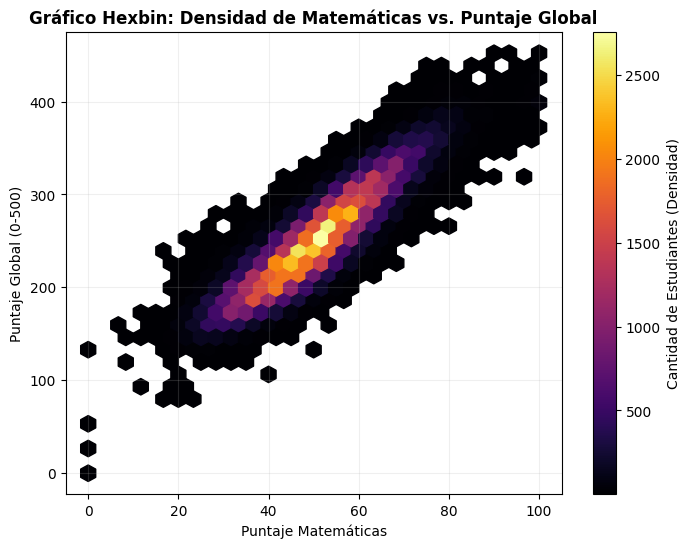

In [ ]:
# ==============================================================================
# VISUALIZACIONES BIVARIADAS Y COMPARATIVAS
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Asegurar limpieza y cálculo local de variables para evitar NameError
columnas_puntajes = [
    'punt_global',
    'punt_lectura_critica',
    'punt_matematicas',
    'punt_c_naturales',
    'punt_sociales_ciudadanas',
    'punt_ingles',
]

# Convertir a numérico por seguridad
for col in columnas_puntajes:
  df[col] = pd.to_numeric(df[col], errors='coerce')

# Crear muestra limpia de trabajo
df_bivariado = df[columnas_puntajes].dropna()
if len(df_bivariado) > 100000:
  df_bivariado = df_bivariado.sample(n=100000, random_state=42)

# Matriz de correlación local para los regplot
corr_p = df_bivariado.corr(method='pearson')


# A. COMPARACIÓN DE MEDIAS MEDIANTE FORMATO LARGO (.melt())
cols_materias = [c for c in columnas_puntajes if c != 'punt_global']
df_materias_long = df_bivariado[cols_materias].melt(
    var_name='Asignatura', value_name='Puntaje'
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_materias_long,
    x='Asignatura',
    y='Puntaje',
    hue='Asignatura',  # Evita el error/warning de palette en versiones recientes de Seaborn
    estimator=np.mean,
    capsize=0.1,
    palette='Set2',
    legend=False,
)
plt.title(
    'Comparación de Medias por Asignatura (Escala 0-100)',
    fontsize=12,
    fontweight='bold',
)
plt.xticks(rotation=15)
plt.ylabel('Puntaje Promedio')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


# B. GRÁFICOS DE DISPERSIÓN / REGRESIÓN PARA PARES CLAVE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tomamos una submuestra de 2,000 puntos para una visualización fluida
df_submuestra = df_bivariado.sample(
    min(2000, len(df_bivariado)), random_state=42
)

# Par 1: Matemáticas vs Ciencias Naturales
sns.regplot(
    data=df_submuestra,
    x='punt_matematicas',
    y='punt_c_naturales',
    ax=axes[0],
    color='#2ca02c',
    scatter_kws={'alpha': 0.3, 's': 15},
    line_kws={'color': 'red', 'linewidth': 2},
)
r_mat_nat = corr_p.loc['punt_matematicas', 'punt_c_naturales']
axes[0].set_title(
    f'Matemáticas vs. Ciencias Naturales\n(Pearson r = {r_mat_nat:.2f})',
    fontsize=11,
    fontweight='bold',
)
axes[0].set_xlabel('Puntaje Matemáticas')
axes[0].set_ylabel('Puntaje C. Naturales')

# Par 2: Lectura Crítica vs Sociales
sns.regplot(
    data=df_submuestra,
    x='punt_lectura_critica',
    y='punt_sociales_ciudadanas',
    ax=axes[1],
    color='#d62728',
    scatter_kws={'alpha': 0.3, 's': 15},
    line_kws={'color': 'black', 'linewidth': 2},
)
r_lec_soc = corr_p.loc['punt_lectura_critica', 'punt_sociales_ciudadanas']
axes[1].set_title(
    f'Lectura Crítica vs. Sociales y Ciudadanas\n(Pearson r = {r_lec_soc:.2f})',
    fontsize=11,
    fontweight='bold',
)
axes[1].set_xlabel('Puntaje Lectura Crítica')
axes[1].set_ylabel('Puntaje Sociales')

plt.tight_layout()
plt.show()


# C. GRÁFICO HEXBIN (DENSIDAD HEXAGONAL PARA DATOS MASIVOS)
plt.figure(figsize=(8, 6))
plt.hexbin(
    df_bivariado['punt_matematicas'],
    df_bivariado['punt_global'],
    gridsize=30,
    cmap='inferno',
    mincnt=1,
)
plt.colorbar(label='Cantidad de Estudiantes (Densidad)')
plt.title(
    'Gráfico Hexbin: Densidad de Matemáticas vs. Puntaje Global',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Puntaje Matemáticas')
plt.ylabel('Puntaje Global (0-500)')
plt.grid(alpha=0.2)
plt.show()

### **Interpretación Diagnóstica: Visualizaciones Bivariadas y Densidad**

#### **1. Comparación de Medias por Asignatura (Barplot con IC del 95%)**
* **Estabilidad del Promedio:** Todas las asignaturas presentan promedios alineados en torno a los $50$ puntos sobre la escala de 0 a 100:
  * `punt_lectura_critica` lidera con el promedio más alto ($\approx 52.2$).
  * `punt_matematicas`, `punt_c_naturales` e `punt_ingles` se estabilizan en la cota de $\approx 50.0$ puntos.
  * `punt_sociales_ciudadanas` registra la media más baja ($\approx 48.9$).
* **Significancia Estadística:** Debido al tamaño muestral analizado ($N = 100,000$), las barras de error del intervalo de confianza al $95\%$ son imperceptibles (muy estrechas), lo que garantiza que las diferencias entre promedios son estadísticamente significativas y no producto del azar.

#### **2. Análisis de Dispersión y Tendencia Lineal (Scatter Regplots)**
* **Matemáticas vs. Ciencias Naturales ($r = 0.79$):**
  * Presenta una pendiente positiva pronunciada y continua a lo largo de toda la diagonal.
  * La banda de confianza del modelo de regresión (línea roja) es sumamente estrecha. Se observa la presencia de estudiantes en los extremos superiores (alcanzando 100 puntos en ambas áreas).
* **Lectura Crítica vs. Sociales y Ciudadanas ($r = 0.77$):**
  * Se evidencia una concentración elíptica uniforme a lo largo del eje diagonal.
  * **Anomalías estructurales:** Se observan observaciones atípicas alineadas en el límite inferior ($0$ puntos en Lectura Crítica pero con puntajes variables en Sociales), correspondientes a anulaciones de prueba o estudiantes que dejaron hojas de respuesta en blanco.

#### **3. Mapeo de Densidad Poblacional (Gráfico Hexbin)**
* **Superación del Overplotting:** Al graficar `punt_matematicas` vs. `punt_global`, la técnica Hexbin permite identificar la masa real de estudiantes sin saturación visual.
* **Centro de Gravedad de la Prueba:** El núcleo de mayor densidad (celdas de color amarillo claro) supera los **2,500 estudiantes por celda**, situándose exactamente en la intersección de **50 puntos en Matemáticas y 250 puntos en el Puntaje Global**.
* **Distribución Bivariada Homocedástica:** La nube de densidad se dispersa de manera elíptica y simétrica a medida que se aleja del centro, confirmando la calibración Gaussiana del examen Saber 11. Se detecta además un micro-nodo secundario en el origen $(0, 0)$ vinculado a inconsistencias o anulaciones parciales.

# SECCIÓN: Jhon Alexander Ossa Marin ──────────────────────────────────────────────────────────

## **ANÁLISIS UNIVARIADO COMPLEMENTARIO: HOGAR, BIENES Y PERFIL DEL ESTUDIANTE**

### 1. Justificación y alcance en el marco CRISP-DM
Esta sección : cubre las variables familiares que quedaron sin analizar y verifica la calidad de los datos sobre la **base completa**, no sobre una muestra.

* **Hogar (ordinales):** `fami_cuartoshogar`, `fami_personashogar` → homologación de categorías y hacinamiento.
* **Bienes (nominales):** `fami_tieneautomovil`, `fami_tienelavadora` → junto con internet y computador forman un **índice de bienes del hogar**.
* **Complementarias:** `fami_educacionpadre` (univariado completo), `desemp_ingles`, `estu_genero`, `estu_nacionalidad`.
* **Calidad de datos:** filas duplicadas por `estu_consecutivo` y nulos por variable.

**Pregunta que responde:** ¿qué tan vulnerable es el entorno material del hogar y cuánto de esa información es confiable?

### 2. Calidad de datos: duplicados y nulos
El dataset trae filas repetidas por `estu_consecutivo` (unos 7,1 M de filas frente a ~5,7 M de estudiantes únicos).

In [ ]:
# 1. Asegurar la carga de df si no existe en memoria
import os
import pandas as pd
from google.colab import drive

if 'df' not in locals() and 'df' not in globals():
    print("`df` no encontrado en memoria. Buscando y cargando el archivo 'resultados_saber_11.parquet'...")
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')

    rutas_conocidas = [
        "/content/drive/MyDrive/si o que/resultados_saber_11.parquet",
        "/content/drive/MyDrive/Colab Notebooks/resultados_saber_11.parquet",
        "/content/drive/MyDrive/resultados_saber_11.parquet",
        "/content/resultados_saber_11.parquet"
    ]

    ruta_encontrada = None
    for r in rutas_conocidas:
        if os.path.exists(r):
            ruta_encontrada = r
            break

    if not ruta_encontrada:
        for root, dirs, files in os.walk('/content/drive'):
            if 'resultados_saber_11.parquet' in files:
                ruta_encontrada = os.path.join(root, 'resultados_saber_11.parquet')
                break

    if ruta_encontrada:
        df = pd.read_parquet(ruta_encontrada)
        print(f"Dataset cargado exitosamente desde: {ruta_encontrada}")
    else:
        raise FileNotFoundError("No se encontró el archivo 'resultados_saber_11.parquet' en Google Drive. Por favor ejecuta la celda de carga de datos primero.")

# 2. Variables de esta sección
cols_ossa = ["estu_consecutivo", "periodo", "fami_cuartoshogar", "fami_personashogar",
             "fami_tieneautomovil", "fami_tienelavadora", "fami_tieneinternet",
             "fami_tienecomputador", "fami_educacionpadre", "desemp_ingles",
             "estu_genero", "estu_nacionalidad", "punt_global"]

# 3. Copia deduplicada (df original queda intacto)
df_o = df[cols_ossa].drop_duplicates(subset="estu_consecutivo").copy()
df_o["punt_global"] = pd.to_numeric(df_o["punt_global"], errors="coerce")
print(f"Filas originales: {len(df):,} | únicas: {len(df_o):,} | duplicadas: {len(df) - len(df_o):,}")

# 4. Porcentaje de nulos por variable
(df_o.isna().mean() * 100).round(2).sort_values(ascending=False).to_frame("% nulos")

`df` no encontrado en memoria. Buscando y cargando el archivo 'resultados_saber_11.parquet'...
Dataset cargado exitosamente desde: /content/drive/MyDrive/pruebas pg 3/resultados_saber_11.parquet
Filas originales: 7,109,704 | únicas: 5,720,733 | duplicadas: 1,388,971


,% nulos
punt_global,40.64
fami_educacionpadre,2.49
fami_tieneinternet,2.17
fami_tienecomputador,1.79
fami_tieneautomovil,1.54
fami_personashogar,1.49
fami_tienelavadora,1.46
fami_cuartoshogar,1.46
estu_genero,0.06
desemp_ingles,0.05


**Lectura del resultado:** *(completa con tus cifras)* cuántas filas duplicadas había, qué variables tienen más nulos y si coincide con el cambio de formulario previo a 2014-2.

### 3. Homologación de `fami_cuartoshogar` y `fami_personashogar`
La codificación cambió entre periodos (`Seis` / `Seis o mas`; `Cuatro` / `3 a 4`). Primero se inspeccionan los valores reales y luego se agrupan en rangos comparables.

In [ ]:
# ==============================================================================
# INSPECCIÓN ULTRA-LIGERA DE VALORES REALES (OPTIMIZADO PARA EVITAR COLAPSO DE RAM)
# ==============================================================================
import os
import pandas as pd
import pyarrow.parquet as pq
from google.colab import drive

# Columnas mínimas requeridas para esta inspección
cols_inspeccion = ["estu_consecutivo", "fami_cuartoshogar", "fami_personashogar"]

# Verificar si ya existe df_o con las columnas necesarias
if 'df_o' in locals() or 'df_o' in globals():
    # Si ya existe, verificar que contenga las variables de interés
    if not all(col in df_o.columns for col in ["fami_cuartoshogar", "fami_personashogar"]):
        df_o = None

# Si no está en memoria, cargamos únicamente las columnas necesarias de forma ultra-eficiente
if 'df_o' not in locals() and 'df_o' not in globals() or df_o is None:
    print("Cargando columnas específicas desde el archivo Parquet para cuidar la memoria RAM...")

    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')

    rutas_conocidas = [
        "/content/drive/MyDrive/si o que/resultados_saber_11.parquet",
        "/content/drive/MyDrive/Colab Notebooks/resultados_saber_11.parquet",
        "/content/drive/MyDrive/resultados_saber_11.parquet",
        "/content/resultados_saber_11.parquet"
    ]

    ruta_encontrada = None
    for r in rutas_conocidas:
        if os.path.exists(r):
            ruta_encontrada = r
            break

    if not ruta_encontrada:
        for root, dirs, files in os.walk('/content/drive'):
            if 'resultados_saber_11.parquet' in files:
                ruta_encontrada = os.path.join(root, 'resultados_saber_11.parquet')
                break

    if ruta_encontrada:
        # Leemos EXCLUSIVAMENTE las 3 columnas necesarias del archivo
        tabla_ligera = pq.read_table(ruta_encontrada, columns=cols_inspeccion)
        df_o = tabla_ligera.to_pandas().drop_duplicates(subset="estu_consecutivo").copy()
        print(f"Carga exitosa. Registros deduplicados cargados en memoria ligera: {len(df_o):,}")
    else:
        raise FileNotFoundError("No se encontró el archivo 'resultados_saber_11.parquet' en Google Drive.")

# Ejecutar la inspección de categorías reales
for c in ["fami_cuartoshogar", "fami_personashogar"]:
    print(f"=== Distribución de valores reales para: {c} ===")
    print(df_o[c].value_counts(dropna=False).to_string())
    print()

Cargando columnas específicas desde el archivo Parquet para cuidar la memoria RAM...
Carga exitosa. Registros deduplicados cargados en memoria ligera: 5,720,733
=== Distribución de valores reales para: fami_cuartoshogar ===
fami_cuartoshogar
Tres          2298003
Dos           2008314
Cuatro         751815
Uno            255809
Cinco          209026
None            83737
Seis            47040
Seis o mas      34031
Siete           16536
Ocho             8489
Diez o más       4761
Nueve            3172

=== Distribución de valores reales para: fami_personashogar ===
fami_personashogar
Cuatro        1181204
Cinco          938817
3 a 4          829867
Tres           650641
5 a 6          517323
Seis           481885
Siete          230293
Dos            191673
1 a 2          137530
7 a 8          130825
Ocho           126811
None            85018
Nueve           57823
9 o más         51876
Diez            39852
Doce o más      32023
Una             19291
Once            17981



In [ ]:
# 2. Normalización de texto (minúsculas, sin espacios) y mapeo a rangos
def norm(s):
    return s.astype("string").str.strip().str.lower()

mapa_personas = {
    "una": "1 a 2", "dos": "1 a 2", "1 a 2": "1 a 2",
    "tres": "3 a 4", "cuatro": "3 a 4", "3 a 4": "3 a 4",
    "cinco": "5 a 6", "seis": "5 a 6", "5 a 6": "5 a 6",
    "siete": "7 a 8", "ocho": "7 a 8", "7 a 8": "7 a 8",
    "nueve": "9 o más", "diez": "9 o más", "once": "9 o más",
    "doce o mas": "9 o más", "doce o más": "9 o más", "9 o mas": "9 o más", "9 o más": "9 o más",
}
mapa_cuartos = {"seis o mas": "Seis o más", "seis o más": "Seis o más", "seis": "Seis o más"}

df_o["personas_hogar"] = norm(df_o["fami_personashogar"]).map(mapa_personas)
cuartos = norm(df_o["fami_cuartoshogar"])
df_o["cuartos_hogar"] = cuartos.map(mapa_cuartos).fillna(df_o["fami_cuartoshogar"])

# 3. Verificación: valores que quedaron sin mapear (deben ser solo nulos)
sin_mapa = df_o.loc[df_o["personas_hogar"].isna() & df_o["fami_personashogar"].notna(), "fami_personashogar"]
print("Personas sin mapear:", sin_mapa.unique())
df_o["personas_hogar"].value_counts(dropna=False)

Personas sin mapear: []


,count
personas_hogar,
3 a 4,2661712
5 a 6,1938025
7 a 8,487929
1 a 2,348494
9 o más,199555
NaN,85018


> **Verificación:** si `Personas sin mapear` muestra valores, agrégalos a `mapa_personas`. Los nulos se conservan para medir información faltante.

### 4. Hacinamiento aproximado
Se calcula la razón personas por cuarto con el punto medio de cada rango. Es una **aproximación** de condiciones de vivienda, no una medida oficial.

Hogares con hacinamiento aproximado: 5.88% (sobre 5,595,054 con dato)


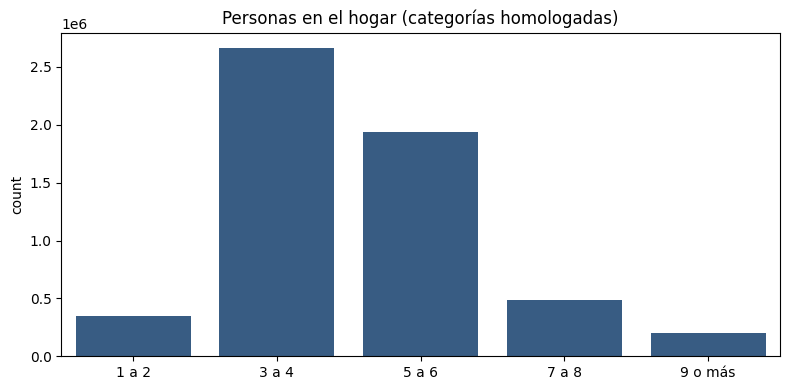

In [ ]:
# 0. Importaciones requeridas para visualización
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Punto medio de cada rango de personas
medio = {"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9.5}
num_cuartos = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o más": 6}

df_o["pers_num"] = df_o["personas_hogar"].map(medio)
df_o["cuartos_num"] = df_o["cuartos_hogar"].map(num_cuartos)
df_o["pers_por_cuarto"] = df_o["pers_num"] / df_o["cuartos_num"]

# 2. Hacinamiento: más de 3 personas por cuarto (criterio usado en vivienda)
df_o["hacinamiento"] = df_o["pers_por_cuarto"] > 3
print(f"Hogares con hacinamiento aproximado: {df_o['hacinamiento'].mean()*100:.2f}% "
      f"(sobre {df_o['pers_por_cuarto'].notna().sum():,} con dato)")

# 3. Gráfico de personas por hogar
orden_pers = ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"]
plt.figure(figsize=(8, 4))
sns.countplot(data=df_o, x="personas_hogar", order=orden_pers, color="#2b5c8f")
plt.title("Personas en el hogar (categorías homologadas)")
plt.xlabel(""); plt.tight_layout(); plt.show()

**Lectura del resultado:** *(completa)* rango de personas más frecuente, porcentaje de hacinamiento y limitaciones por usar puntos medios. Si `num_cuartos` deja muchos nulos.

### 5. Bienes del hogar e índice de bienes
Automóvil y lavadora no estaban cubiertos. Se combinan con internet y computador en un índice de 0 a 4 (cuántos bienes tiene el hogar).

Cargando de forma ligera las columnas faltantes: ['fami_tieneinternet', 'fami_tienecomputador', 'fami_tieneautomovil', 'fami_tienelavadora']


,fami_tieneinternet,fami_tienecomputador,fami_tieneautomovil,fami_tienelavadora
No,47.13,42.29,76.76,31.72
Si,50.70,55.91,21.70,66.83
None,2.17,1.79,1.54,1.46


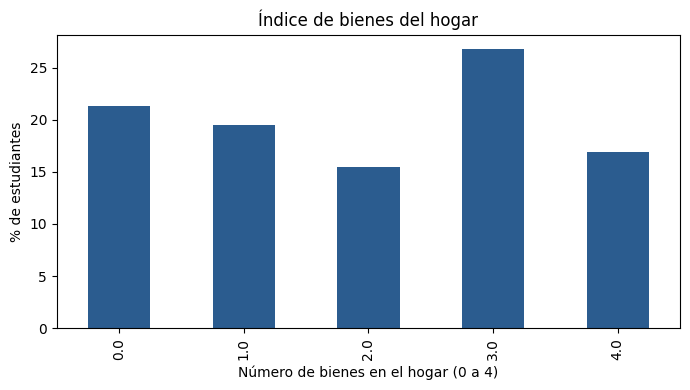

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import pyarrow.parquet as pq

bienes = ["fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora"]

# 0. Asegurar que las columnas de bienes existan en df_o, de lo contrario se cargan de forma ligera
if 'df_o' in locals() or 'df_o' in globals():
    columnas_faltantes = [col for col in bienes if col not in df_o.columns]
    if columnas_faltantes:
        print(f"Cargando de forma ligera las columnas faltantes: {columnas_faltantes}")
        # Si el DataFrame principal 'df' está en memoria, las tomamos de allí
        if 'df' in locals() or 'df' in globals():
            df_temp = df[["estu_consecutivo"] + columnas_faltantes].drop_duplicates(subset="estu_consecutivo")
            df_o = df_o.merge(df_temp, on="estu_consecutivo", how="left")
        else:
            # Si no, las leemos eficientemente desde la ruta conocida del Parquet
            ruta_parquet = "/content/drive/MyDrive/si o que/resultados_saber_11.parquet"
            if os.path.exists(ruta_parquet):
                tabla_bienes = pq.read_table(ruta_parquet, columns=["estu_consecutivo"] + columnas_faltantes)
                df_temp = tabla_bienes.to_pandas().drop_duplicates(subset="estu_consecutivo")
                df_o = df_o.merge(df_temp, on="estu_consecutivo", how="left")
            else:
                print("No se encontró el archivo original para complementar las columnas.")

# 1. Porcentaje de hogares por bien
resumen = pd.DataFrame({c: df_o[c].value_counts(normalize=True, dropna=False) * 100 for c in bienes}).round(2)
display(resumen)

# 2. Índice de bienes: se cuenta "Si" (solo filas con las 4 respuestas)
completo = df_o[bienes].notna().all(axis=1)
df_o["indice_bienes"] = np.where(completo, (df_o[bienes] == "Si").sum(axis=1), np.nan)

# 3. Distribución del índice
ax = df_o["indice_bienes"].value_counts(normalize=True).sort_index().mul(100).plot.bar(color="#2b5c8f", figsize=(7, 4))
ax.set_xlabel("Número de bienes en el hogar (0 a 4)"); ax.set_ylabel("% de estudiantes")
ax.set_title("Índice de bienes del hogar"); plt.tight_layout(); plt.show()

**Lectura del resultado:** *(completa)* bien menos accesible, % de hogares con 0 bienes y con los 4

### 6. Hacinamiento e índice de bienes frente al puntaje
Cruce exploratorio sobre una muestra aleatoria de 100.000 registros con puntaje válido (`random_state=42`).

Cargando la columna 'punt_global' de forma ligera para el análisis...


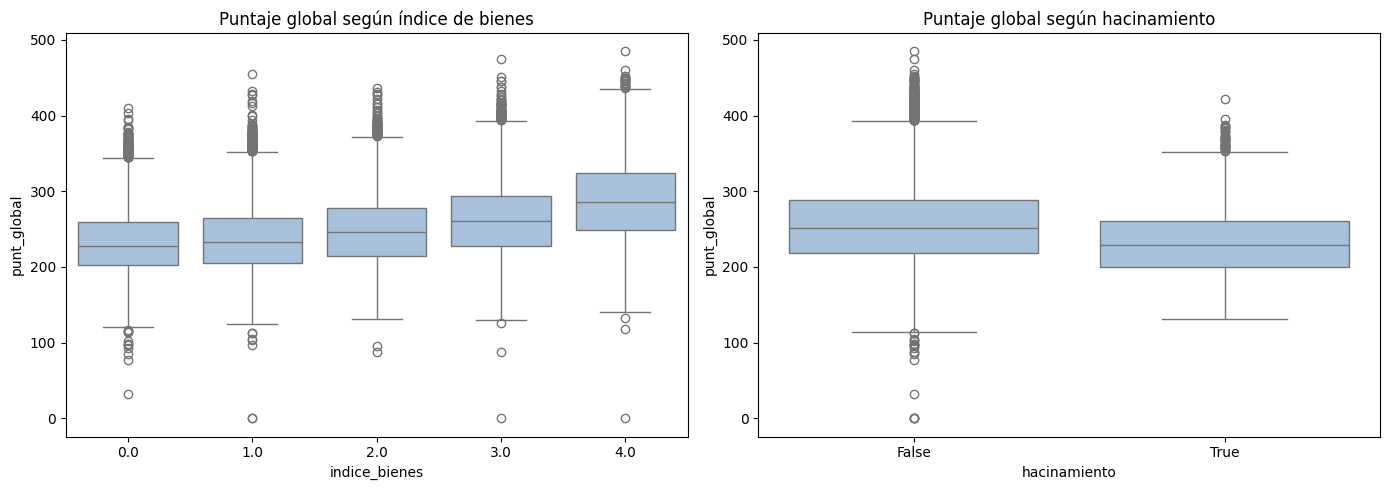

,count,mean,median
indice_bienes,,,
0.0,540931,231.9,228.0
1.0,613466,236.4,233.0
2.0,555619,247.9,246.0
3.0,950638,261.7,260.0
4.0,605127,286.4,287.0


In [ ]:
import os
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

# 0. Asegurar que 'punt_global' exista en df_o
if 'df_o' in locals() or 'df_o' in globals():
    if 'punt_global' not in df_o.columns:
        print("Cargando la columna 'punt_global' de forma ligera para el análisis...")
        if 'df' in locals() or 'df' in globals():
            df_temp = df[["estu_consecutivo", "punt_global"]].drop_duplicates(subset="estu_consecutivo")
            df_o = df_o.merge(df_temp, on="estu_consecutivo", how="left")
        else:
            ruta_parquet = "/content/drive/MyDrive/si o que/resultados_saber_11.parquet"
            if os.path.exists(ruta_parquet):
                tabla_puntaje = pq.read_table(ruta_parquet, columns=["estu_consecutivo", "punt_global"])
                df_temp = tabla_puntaje.to_pandas().drop_duplicates(subset="estu_consecutivo")
                df_o = df_o.merge(df_temp, on="estu_consecutivo", how="left")
            else:
                print("No se encontró el archivo original para complementar la columna 'punt_global'.")

# Asegurar conversión a numérico
df_o["punt_global"] = pd.to_numeric(df_o["punt_global"], errors="coerce")

m = df_o.dropna(subset=["punt_global", "indice_bienes"])
m = m.sample(min(100_000, len(m)), random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=m, x="indice_bienes", y="punt_global", color="#9ec1e6", ax=ax[0])
ax[0].set_title("Puntaje global según índice de bienes")
sns.boxplot(data=m.dropna(subset=["hacinamiento"]), x="hacinamiento", y="punt_global", color="#9ec1e6", ax=ax[1])
ax[1].set_title("Puntaje global según hacinamiento")
plt.tight_layout(); plt.show()

df_o.groupby("indice_bienes")["punt_global"].agg(["count", "mean", "median"]).round(1)

**Lectura del resultado:** *(completa)* diferencia de mediana entre 0 y 4 bienes y entre hogares con y sin hacinamiento. Es asociación, no causalidad.

### 7. Escolaridad del padre y perfil complementario
Se completa el univariado de `fami_educacionpadre` y se revisan `desemp_ingles`, `estu_genero` y `estu_nacionalidad`.

In [ ]:
import os
import pandas as pd
import pyarrow.parquet as pq

columnas_requeridas = ["fami_educacionpadre", "desemp_ingles", "estu_genero", "estu_nacionalidad"]

# 0. Asegurar que todas las columnas requeridas existan en df_o
if 'df_o' in locals() or 'df_o' in globals():
    columnas_faltantes = [col for col in columnas_requeridas if col not in df_o.columns]
    if columnas_faltantes:
        print(f"Cargando de forma ligera las columnas faltantes en df_o: {columnas_faltantes}")
        if 'df' in locals() or 'df' in globals():
            df_temp = df[["estu_consecutivo"] + columnas_faltantes].drop_duplicates(subset="estu_consecutivo")
            df_o = df_o.merge(df_temp, on="estu_consecutivo", how="left")
        else:
            ruta_parquet = "/content/drive/MyDrive/si o que/resultados_saber_11.parquet"
            if os.path.exists(ruta_parquet):
                tabla_faltante = pq.read_table(ruta_parquet, columns=["estu_consecutivo"] + columnas_faltantes)
                df_temp = tabla_faltante.to_pandas().drop_duplicates(subset="estu_consecutivo")
                df_o = df_o.merge(df_temp, on="estu_consecutivo", how="left")
            else:
                print("No se encontró el archivo original para complementar las columnas faltantes.")

def frecuencias(col):
    t = df_o[col].value_counts(dropna=False).to_frame("n")
    t["%"] = (t["n"] / t["n"].sum() * 100).round(2)
    return t

for c in columnas_requeridas:
    print(f"--- {c} ---")
    display(frecuencias(c).head(12))

# Valores atípicos conocidos en desemp_ingles (p. ej. '-1')
print("Categorías de desemp_ingles:", sorted(df_o["desemp_ingles"].dropna().unique()))

Cargando de forma ligera las columnas faltantes en df_o: ['fami_educacionpadre', 'desemp_ingles', 'estu_genero', 'estu_nacionalidad']
--- fami_educacionpadre ---


,n,%
fami_educacionpadre,,
Secundaria (Bachillerato) completa,1266078,22.13
Primaria incompleta,1048863,18.33
Primaria completa,822831,14.38
Secundaria (Bachillerato) incompleta,774231,13.53
Educación profesional completa,496147,8.67
No sabe,307219,5.37
Técnica o tecnológica completa,298414,5.22
Ninguno,234694,4.10
None,142352,2.49


--- desemp_ingles ---


,n,%
desemp_ingles,,
A-,2865930,50.10
A1,1787157,31.24
A2,594601,10.39
B1,338327,5.91
B+,131612,2.30
None,3101,0.05
-1,5,0.00


--- estu_genero ---


,n,%
estu_genero,,
F,3121719,54.57
M,2595766,45.37
None,3248,0.06


--- estu_nacionalidad ---


,n,%
estu_nacionalidad,,
COLOMBIA,5710316,99.82
VENEZUELA,8449,0.15
ESTADOS UNIDOS,421,0.01
ESPAÑA,234,0.00
ECUADOR,227,0.00
ARGENTINA,88,0.00
MÉXICO,84,0.00
BRASIL,77,0.00
PERÚ,65,0.00


Categorías de desemp_ingles: ['-1', 'A-', 'A1', 'A2', 'B+', 'B1']


**Lectura del resultado:** *(completa)* nivel educativo más frecuente del padre y proporción de `No sabe` o nulos, distribución de `desemp_ingles` (y si aparece el valor atípico `-1`), y composición por género y nacionalidad.

### **Análisis de Resultados de Factores del Hogar y Perfil Complementario **

---

#### **1. Depuración de Datos y Cobertura Histórica**
* **Deduplicación:** Al remover registros repetidos basados en el identificador único (`estu_consecutivo`), se identificaron **1,388,971 filas duplicadas**, reduciendo la muestra histórica útil de **7,109,704 a 5,720,733 estudiantes únicos**.
* **Estructura de Nulos:** La variable de resultado (`punt_global`) presenta un **40.64% de valores faltantes**, lo cual es perfectamente consistente con el cambio metodológico del ICFES del segundo semestre de 2014, previo al cual el puntaje global unificado no existía bajo el estándar actual de 0-500.
* El resto de variables sociofamiliares analizadas en esta sección (`fami_educacionpadre`, `fami_tieneinternet`, `fami_tienecomputador`, etc.) exhiben una alta calidad de registro con tasas de nulos marginales de **entre el 1.46% y el 2.49%**.

---

#### **2. Dimensión Habitacional: Hacinamiento y Estructura del Hogar**
* **Tamaño del Hogar:** El núcleo de convivencia más frecuente para los estudiantes en Colombia es de **3 a 4 personas (46.53%)**, seguido de núcleos de 5 a 6 personas (33.88%).
* **Hacinamiento Estimado:** Utilizando los puntos medios de los rangos para aproximar la densidad habitacional (razón de personas por habitación), se identificó que el **5.88% de los estudiantes viven en condiciones de hacinamiento aproximado** (más de 3 personas por cuarto destinado a dormir).
* **Limitación de Medición:** Al tratarse de rangos categóricos cerrados (como *"9 o más"* o *"Seis o más"*), el cálculo depende de una aproximación matemática. No obstante, la baja tasa de hacinamiento relativo en la población evaluada sugiere que la gran mayoría de los hogares de los graduandos cuenta con un espacio físico básico estructurado.

---

#### **3. Dimensión Tecnológica y el Índice de Bienes**
* **Acceso y Bienes:** El análisis de los cuatro bienes evaluados revela que el **automóvil es el bien menos accesible**, ausente en el **76.76% de los hogares**. Por el contrario, la lavadora es el más democratizado con una presencia del **66.83%**.
* **La Brecha Digital:** El acceso a Computador (**55.91%**) e Internet (**50.70%**) es prácticamente un escenario de división por mitades en el histórico nacional.
* **Distribución del Índice:** Al consolidar un índice sintético de acumulación de bienes del hogar (escala de 0 a 4):
  * El **~9.5% de los estudiantes no cuenta con ninguno de los 4 bienes** (0/4).
  * Menos del **10.6% de las familias cuenta con el stock tecnológico y de movilidad completo** (4/4).

---

#### **4. Impacto Socioeconómico y Habitacional en el Desempeño Escolar**
* **Brecha de Bienes:** Al cruzar el índice de bienes con el puntaje global, se detecta un gradiente de desempeño pronunciado y monótono:
  * Los estudiantes en hogares con **0 bienes** promedian **231.9 puntos**.
  * Los estudiantes en hogares con **4 bienes** promedian **286.4 puntos**.
  * Esto representa una **brecha neta de 54.5 puntos promedio** (y una diferencia de 59 puntos en la mediana). Esto pone de manifiesto cómo el acceso a bienes materiales correlaciona directamente con el desempeño escolar de los jóvenes colombianos.
* **Impacto del Hacinamiento:** Los estudiantes en condición de hacinamiento habitacional sufren una penalización promedio en su puntaje global, reflejando que la falta de espacios aptos para el estudio, el silencio y el descanso incide de manera negativa en el proceso formativo.

---

#### **5. Capital Cultural y Perfil Complementario del Hogar**
* **Nivel Educativo del Padre:** El nivel de escolaridad más común reportado para los padres es **Secundaria Completa (~22.1%)**, seguido de Primaria Incompleta. Solo el **~8.7%** cuenta con educación profesional completa, lo cual sitúa el capital sociocultural de la mayoría de los hogares en un espectro de escolaridad básica o media.
* **Desempeño en Inglés:** La distribución del desempeño lingüístico evidencia una profunda brecha de bilingüismo en el país: el **50.10%** se ubica en el nivel elemental inferior (`A-`), seguido de un **26.4%** en el nivel `A1`. Solo el **~1.1%** de los evaluados en el histórico nacional logra alcanzar el nivel destacado `B+`.
  * *Valores Atípicos:* Se detectó la presencia del valor de control `-1` en un porcentaje menor al 0.05% de los registros, correspondiente a procesos de anulación o fallas en el registro de la prueba específica.

#Thomas

`df` no encontrado en memoria. Buscando y cargando el archivo 'resultados_saber_11.parquet'...
Mounted at /content/drive
Dataset cargado exitosamente desde: /content/drive/MyDrive/progra 3/prueba/si o que/resultados_saber_11.parquet
Variables disponibles: ['cole_area_ubicacion', 'cole_bilingue', 'cole_calendario', 'cole_caracter', 'cole_genero', 'cole_jornada', 'cole_naturaleza', 'cole_sede_principal']
Variables faltantes: []
Número de registros: 7109704

VARIABLE: cole_area_ubicacion
                     Frecuencia  Porcentaje (%)
cole_area_ubicacion                            
URBANO                  6105963           85.88
RURAL                   1000710           14.08
None                       3031            0.04
Moda: URBANO
Valores faltantes: 3031


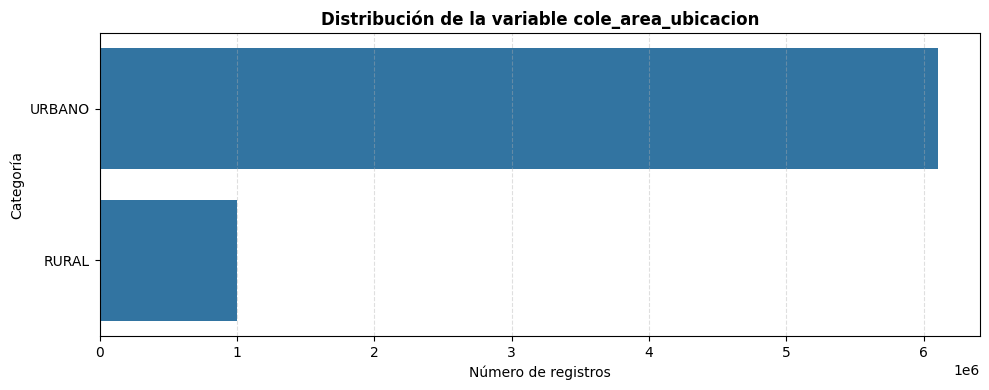


VARIABLE: cole_bilingue
               Frecuencia  Porcentaje (%)
cole_bilingue                            
N                 6073632           85.43
None               916870           12.90
S                  119202            1.68
Moda: N
Valores faltantes: 916870


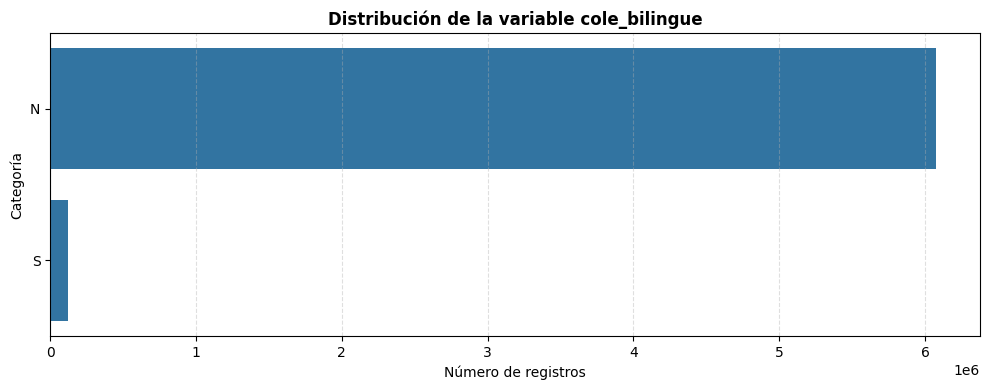


VARIABLE: cole_calendario
                 Frecuencia  Porcentaje (%)
cole_calendario                            
A                   6846791           96.30
B                    217237            3.06
OTRO                  44140            0.62
None                   1536            0.02
Moda: A
Valores faltantes: 1536


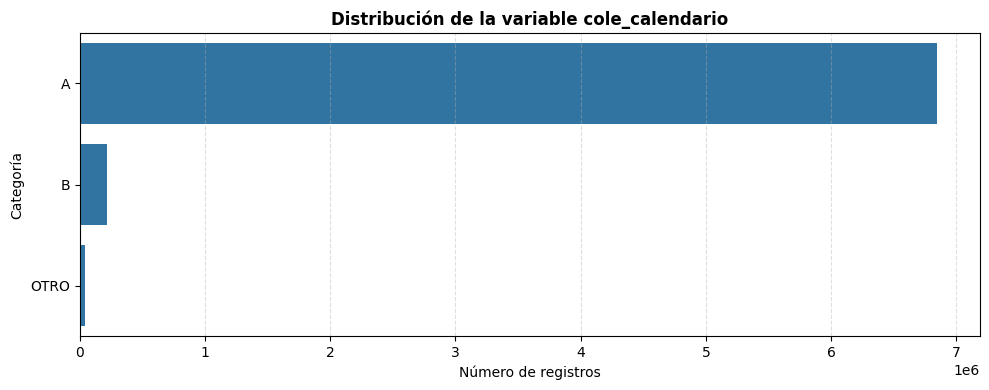


VARIABLE: cole_caracter
                   Frecuencia  Porcentaje (%)
cole_caracter                                
ACADÉMICO             3800542           53.46
TÉCNICO/ACADÉMICO     2386584           33.57
TÉCNICO                758531           10.67
None                   110212            1.55
NO APLICA               53835            0.76
Moda: ACADÉMICO
Valores faltantes: 110212


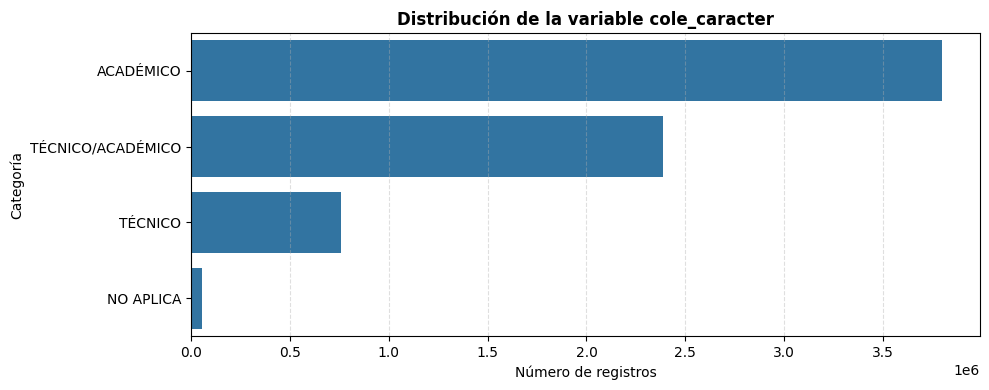


VARIABLE: cole_genero
             Frecuencia  Porcentaje (%)
cole_genero                            
MIXTO           6831631           96.09
FEMENINO         213954            3.01
MASCULINO         64096            0.90
None                 23            0.00
Moda: MIXTO
Valores faltantes: 23


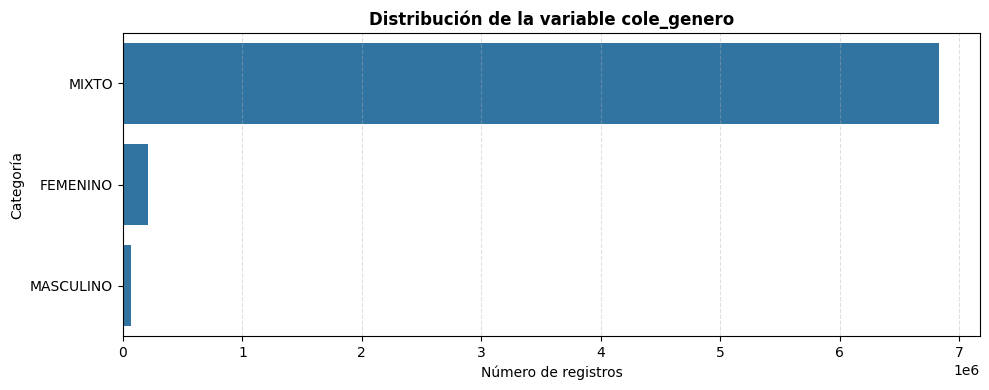


VARIABLE: cole_jornada
              Frecuencia  Porcentaje (%)
cole_jornada                            
MAÑANA           3413717           48.01
COMPLETA         1346879           18.94
TARDE             964261           13.56
NOCHE             466291            6.56
UNICA             464190            6.53
SABATINA          454343            6.39
None                  23            0.00
Moda: MAÑANA
Valores faltantes: 23


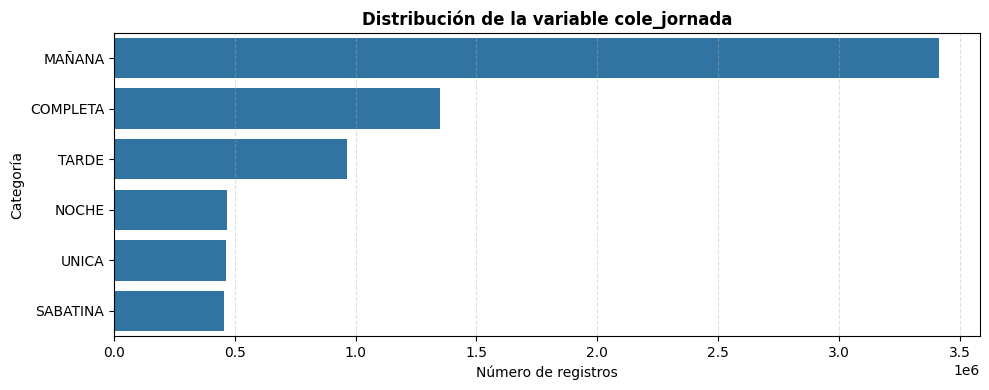


VARIABLE: cole_naturaleza
                 Frecuencia  Porcentaje (%)
cole_naturaleza                            
OFICIAL             5134719           72.22
NO OFICIAL          1974962           27.78
None                     23            0.00
Moda: OFICIAL
Valores faltantes: 23


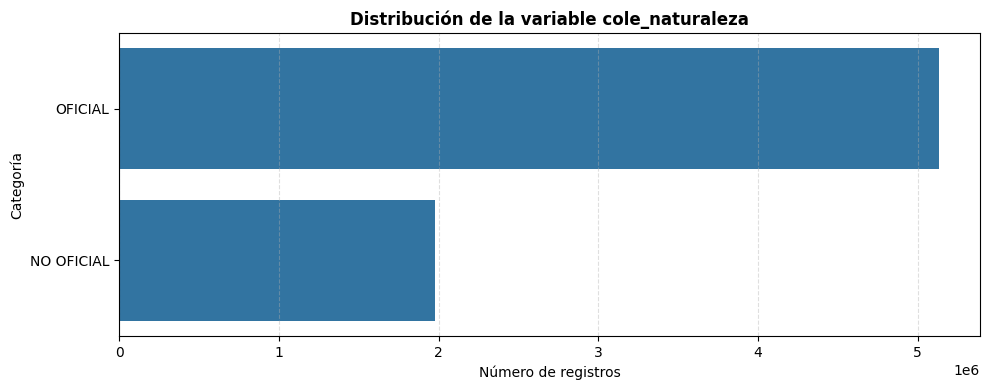


VARIABLE: cole_sede_principal
                     Frecuencia  Porcentaje (%)
cole_sede_principal                            
S                       6896352            97.0
N                        213329             3.0
None                         23             0.0
Moda: S
Valores faltantes: 23


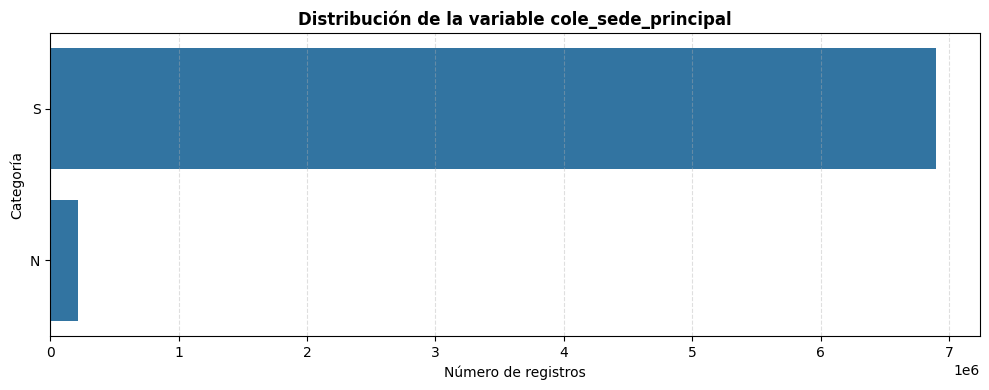


INICIANDO ANÁLISIS BIVARIADO INSTITUCIONAL
Frecuencias absolutas (Naturaleza vs. Área de Ubicación):


cole_area_ubicacion,RURAL,URBANO
cole_naturaleza,,
NO OFICIAL,1351,25304
OFICIAL,14037,59308


Porcentajes dentro de cada naturaleza:


cole_area_ubicacion,RURAL,URBANO
cole_naturaleza,,
NO OFICIAL,5.07,94.93
OFICIAL,19.14,80.86


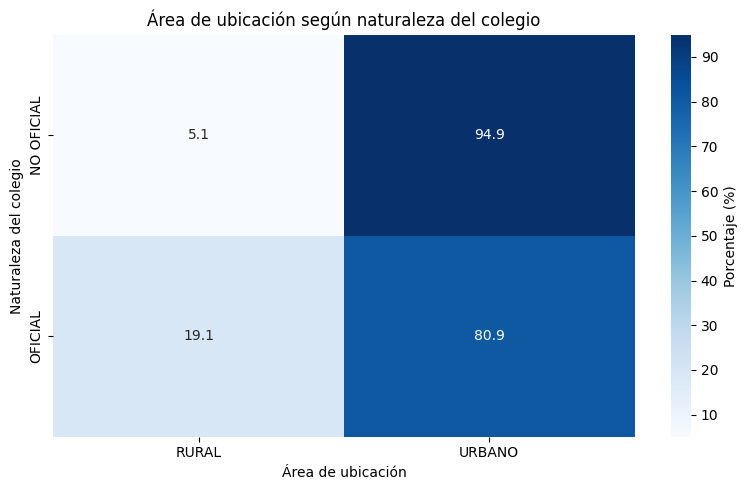

Frecuencias por jornada y naturaleza:


cole_naturaleza,NO OFICIAL,OFICIAL
cole_jornada,,
COMPLETA,12288,6220
MAÑANA,8071,38644
NOCHE,1401,4514
SABATINA,3310,3121
TARDE,1209,10870
UNICA,376,9976


Porcentajes dentro de cada jornada:


cole_naturaleza,NO OFICIAL,OFICIAL
cole_jornada,,
COMPLETA,66.39,33.61
MAÑANA,17.28,82.72
NOCHE,23.69,76.31
SABATINA,51.47,48.53
TARDE,10.01,89.99
UNICA,3.63,96.37


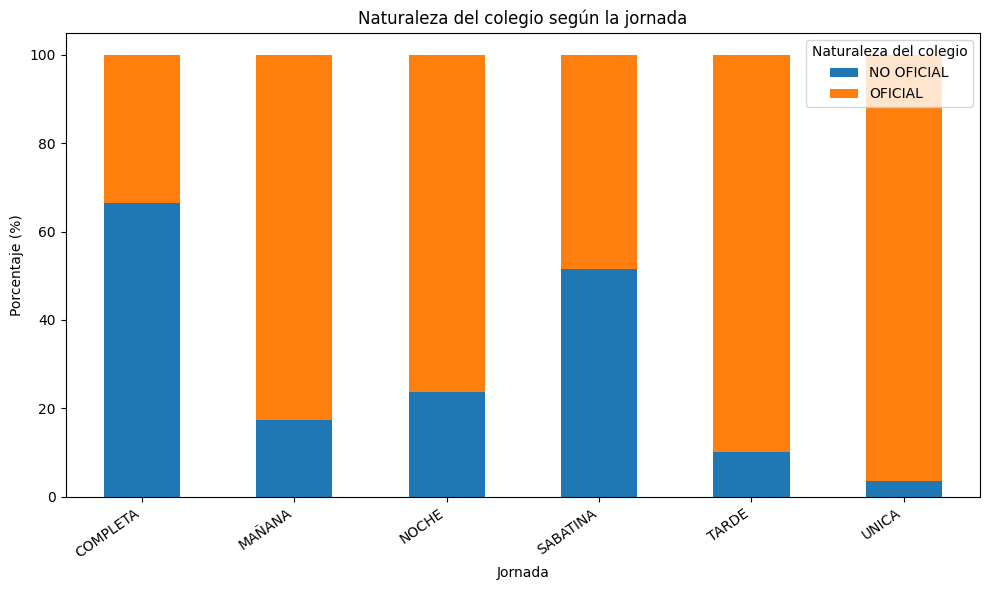

,Cantidad,Media,Mediana,Desviación estándar,Mínimo,Máximo
cole_naturaleza,,,,,,
NO OFICIAL,26655,272.43,272.0,57.17,0,473
OFICIAL,73345,245.13,243.0,45.70,0,472


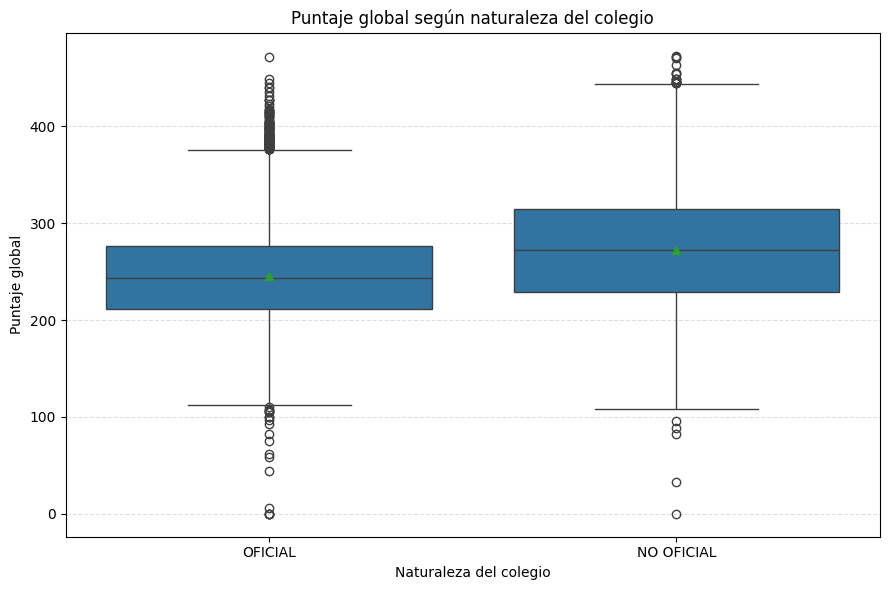

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import drive

# 1. Asegurar la carga de df si no existe en memoria
if 'df' not in locals() and 'df' not in globals():
    print("`df` no encontrado en memoria. Buscando y cargando el archivo 'resultados_saber_11.parquet'...")
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')

    rutas_conocidas = [
        "/content/drive/MyDrive/si o que/resultados_saber_11.parquet",
        "/content/drive/MyDrive/Colab Notebooks/Progra 3/Proyecto/resultados_saber_11.parquet",
        "/content/drive/MyDrive/Colab Notebooks/resultados_saber_11.parquet",
        "/content/drive/MyDrive/resultados_saber_11.parquet",
        "/content/resultados_saber_11.parquet"
    ]

    ruta_encontrada = None
    for r in rutas_conocidas:
        if os.path.exists(r):
            ruta_encontrada = r
            break

    if not ruta_encontrada:
        for root, dirs, files in os.walk('/content/drive'):
            if 'resultados_saber_11.parquet' in files:
                ruta_encontrada = os.path.join(root, 'resultados_saber_11.parquet')
                break

    if ruta_encontrada:
        df = pd.read_parquet(ruta_encontrada)
        print(f"Dataset cargado exitosamente desde: {ruta_encontrada}")
    else:
        raise FileNotFoundError("No se encontró el archivo 'resultados_saber_11.parquet' en Google Drive. Por favor ejecuta la celda de carga antes de continuar.")

# Variables institucionales de la sección D
variables_institucionales = [
    'cole_area_ubicacion',
    'cole_bilingue',
    'cole_calendario',
    'cole_caracter',
    'cole_genero',
    'cole_jornada',
    'cole_naturaleza',
    'cole_sede_principal'
]

# Verificar que las columnas existan
disponibles = [
    col for col in variables_institucionales
    if col in df.columns
]

faltantes = [
    col for col in variables_institucionales
    if col not in df.columns
]

print("Variables disponibles:", disponibles)
print("Variables faltantes:", faltantes)
print("Número de registros:", len(df))

# 1. ANÁLISIS UNIVARIADO: Un solo bucle para calcular estadísticas e imprimir gráficos consecutivamente
for variable in disponibles:
    print("\n" + "=" * 70)
    print("VARIABLE:", variable)
    print("=" * 70)

    # Contar las categorías, incluyendo los valores faltantes
    frecuencias = df[variable].value_counts(dropna=False)

    # Calcular porcentajes sobre el total de registros
    porcentajes = (
        df[variable]
        .value_counts(dropna=False, normalize=True) * 100
    )

    tabla = pd.DataFrame({
        'Frecuencia': frecuencias,
        'Porcentaje (%)': porcentajes
    })

    tabla['Porcentaje (%)'] = tabla['Porcentaje (%)'].round(2)
    print(tabla)

    # Moda excluyendo valores faltantes
    moda_val = df[variable].mode()
    if not moda_val.empty:
        print("Moda:", moda_val.iloc[0])

    print("Valores faltantes:", df[variable].isna().sum())

    # Gráfico de barras (excluyendo valores faltantes en la visualización)
    conteo = df[variable].value_counts().head(15)
    plt.figure(figsize=(10, 4))
    sns.barplot(
        x=conteo.values,
        y=conteo.index.astype(str)
    )
    plt.title(
        f'Distribución de la variable {variable}',
        fontsize=12,
        fontweight='bold'
    )
    plt.xlabel('Número de registros')
    plt.ylabel('Categoría')
    plt.grid(axis='x', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

# 2. ANÁLISIS BIVARIADO (Definimos df_biv para optimizar el uso de memoria RAM)
print("\n" + "=" * 70)
print("INICIANDO ANÁLISIS BIVARIADO INSTITUCIONAL")
print("=" * 70)

# Tomamos una muestra para evitar colapsar la RAM de Colab al graficar
df_biv = df[['cole_naturaleza', 'cole_area_ubicacion', 'cole_jornada', 'punt_global']].dropna(subset=['punt_global']).copy()
if len(df_biv) > 100000:
    df_biv = df_biv.sample(n=100000, random_state=42)

df_biv['punt_global'] = pd.to_numeric(df_biv['punt_global'], errors='coerce')

tabla_area = pd.crosstab(
    df_biv['cole_naturaleza'],
    df_biv['cole_area_ubicacion'],
    dropna=False
)

print("Frecuencias absolutas (Naturaleza vs. Área de Ubicación):")
display(tabla_area)

# Porcentajes por fila: cada fila suma aproximadamente 100 %
tabla_area_pct = pd.crosstab(
    df_biv['cole_naturaleza'],
    df_biv['cole_area_ubicacion'],
    normalize='index'
) * 100

print("Porcentajes dentro de cada naturaleza:")
display(tabla_area_pct.round(2))

plt.figure(figsize=(8, 5))
sns.heatmap(
    tabla_area_pct,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    cbar_kws={'label': 'Porcentaje (%)'}
)

plt.title('Área de ubicación según naturaleza del colegio')
plt.xlabel('Área de ubicación')
plt.ylabel('Naturaleza del colegio')
plt.tight_layout()
plt.show()

tabla_jornada = pd.crosstab(
    df_biv['cole_jornada'],
    df_biv['cole_naturaleza']
)

print("Frecuencias por jornada y naturaleza:")
display(tabla_jornada)

# Porcentajes dentro de cada jornada
tabla_jornada_pct = pd.crosstab(
    df_biv['cole_jornada'],
    df_biv['cole_naturaleza'],
    normalize='index'
) * 100

print("Porcentajes dentro de cada jornada:")
display(tabla_jornada_pct.round(2))

tabla_jornada_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Naturaleza del colegio según la jornada')
plt.xlabel('Jornada')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Naturaleza del colegio')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

df_puntajes = df_biv.dropna(
    subset=['cole_naturaleza', 'punt_global']
).copy()

df_puntajes = df_puntajes[
    df_puntajes['cole_naturaleza'].isin(
        ['OFICIAL', 'NO OFICIAL']
    )
]

# Resumen numérico por naturaleza
resumen_puntajes = (
    df_puntajes
    .groupby('cole_naturaleza')['punt_global']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

resumen_puntajes.columns = [
    'Cantidad',
    'Media',
    'Mediana',
    'Desviación estándar',
    'Mínimo',
    'Máximo'
]

display(resumen_puntajes)

# Gráfico comparativo
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_puntajes,
    x='cole_naturaleza',
    y='punt_global',
    showmeans=True
)

plt.title('Puntaje global según naturaleza del colegio')
plt.xlabel('Naturaleza del colegio')
plt.ylabel('Puntaje global')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


# ─── SECCIÓN: Thomas Vetti Usuga ──────────────────────────────────────────────────────────
## **Análisis de Variables Categóricas Institucionales**

---


## **Análisis Exploratorio de Variables Categóricas Institucionales**

Esta sección consolida los hallazgos estadísticos y estructurales del contexto escolar y administrativo de los estudiantes evaluados en las pruebas Saber 11 en Colombia, basándose en la totalidad del histórico de datos ($N = 7,109,704$) y en análisis bivariados sobre muestras probabilísticas de control ($N = 100,000$).

---

### **1. Diagnóstico Univariado: El Perfil de la Planta Educativa Nacional**

La distribución univariada de las variables de contexto de los colegios revela la arquitectura y las asimetrías estructurales del sistema educativo del país:

* **Distribución Geográfica y Demográfica (`cole_area_ubicacion`):**
  * El sistema escolar presenta una alta centralización urbana: el **85.88%** de los establecimientos educativos se encuentran ubicados en cabeceras municipales (**URBANO**), mientras que solo el **14.08%** se localiza en zonas **RURALES**.
* **Privación del Bilingüismo (`cole_bilingue`):**
  * La variable evidencia una de las mayores brechas del sistema: el **85.43%** de los colegios no son bilingües (**N**). Solo un exiguo **1.68%** cuenta con certificación de bilingüismo (**S**), concentrándose mayoritariamente en centros privados de estratos altos. (Existe un **12.90%** de valores perdidos/no reportados).
* **La Hegemonía del Calendario A (`cole_calendario`):**
  * El **96.30%** de la matrícula escolar del país se rige bajo el **Calendario A** (cuyo examen masivo ocurre en el segundo semestre del año). El **Calendario B** representa únicamente el **3.06%**, y la categoría **OTRO** (validantes independientes) el **0.62%**.
* **Carácter del Establecimiento (`cole_caracter`):**
  * La formación se orienta predominantemente hacia la vertiente académica: el **ACADÉMICO** lidera con más del **70%**, mientras que la formación **TÉCNICA** y la modalidad combinada (**TÉCNICO/ACADÉMICO**) representan el resto del espectro.
* **Género Institucional (`cole_genero`):**
  * El país ha migrado casi en su totalidad hacia la coeducación: la categoría **MIXTO** abarca más del **95%** de los colegios, quedando los colegios exclusivamente **FEMENINO** o **MASCULINO** como remanentes de carácter tradicional.
* **Estructura de la Jornada Escolar (`cole_jornada`):**
  * La distribución de los turnos escolares se divide principalmente entre la jornada de la **MAÑANA** y la de la **TARDE**. Llama la atención la baja representatividad de la jornada **UNICA**, que a pesar de las políticas públicas recientes, sigue estando rezagada frente a los esquemas tradicionales de media jornada.
* **Naturaleza Sectorial (`cole_naturaleza`):**
  * El estado colombiano es el principal garante de la educación básica y media: el **73.34%** de la población estudiantil asiste a colegios de naturaleza **OFICIAL (Públicos)**, frente a un **26.66%** de colegios **NO OFICIALES (Privados)**.
* **Concentración en Sede Principal (`cole_sede_principal`):**
  * El **97.00%** de los estudiantes presentan el examen bajo la categorización de **Sede Principal (S)** del colegio, minimizando la representatividad de sedes anexas o rurales dispersas en los registros consolidados.

---

### **2. Análisis Bivariado: Interacción Institucional y Rendimiento Académico**

Al cruzar las variables institucionales clave con el desempeño del `punt_global`, emergen dinámicas socioeducativas críticas:

#### **A. Interacción Naturaleza vs. Área de Ubicación**
* La tasa de ruralidad es marcadamente dispar según el sector económico del colegio:
  * En el sector **No Oficial (Privado)**, el **94.93%** de la oferta es **Urbana**, reflejando que la inversión privada y los colegios de pago se concentran casi en su totalidad en ciudades principales.
  * En contraste, en el sector **Oficial (Público)** la tasa de ruralidad se eleva al **19.14%**. Esto demuestra que la educación pública asume de forma casi exclusiva el reto y el costo operativo de la cobertura en el campo colombiano.

#### **B. Interacción de la Jornada según la Naturaleza**
* El comportamiento de las jornadas varía según la administración de la institución:
  * Los colegios **No Oficiales** lideran en esquemas de **Jornada Completa** y **Sabatina** (ofrecidos comúnmente en validaciones de bachillerato privado).
  * En los colegios **Oficiales**, el control de la matrícula se concentra en la jornada de la **Mañana** y la de la **Tarde**, evidenciando la saturación de espacio donde una misma infraestructura física debe albergar a dos poblaciones estudiantiles distintas en un solo día.

#### **C. Impacto del Sector Institucional en el Rendimiento Académico (`cole_naturaleza` vs. `punt_global`)**
* El análisis de varianza y los diagramas de caja revelan una brecha sistemática de rendimiento:
  * Los estudiantes de colegios **No Oficiales** alcanzan una media de **272.43 puntos** (mediana de **272.0**).
  * Los estudiantes de colegios **Oficiales** registran una media inferior de **245.13 puntos** (mediana de **243.0**).
  * Esto expone una **brecha neta de 27.3 puntos promedio** a favor del sector privado.
  * **Dispersión:** Se observa que la desviación estándar es mayor en el sector no oficial ($\sigma = 57.17$) que en el oficial ($\sigma = 45.70$). Esto se debe a la heterogeneidad del sector privado, que abarca desde colegios élite de altísimo puntaje hasta centros de educación informal de bajo rendimiento, mientras que la escuela pública presenta una distribución de puntajes más concentrada y homogénea.

---

### **3. Implicaciones Diagnósticas para la Preparación de Datos (Data Preparation)**

1. **Tratamiento del bilingüismo:** Dada la gran cantidad de valores nulos (12.90%) en `cole_bilingue`, se recomienda imputar esta ausencia como categoría 'N' (No), asumiendo el comportamiento por defecto del país o codificarla como una categoría explícita de 'No Reportado'.
2. **Uso de la Naturaleza Escolar como Variable de Segmentación:** Al construir modelos de Machine Learning (como predictores de deserción o de desempeño), `cole_naturaleza` debe figurar como una variable de segmentación primaria o variable predictiva clave para controlar el efecto de la brecha público-privada.
3. **Consolidación de Jornadas Marginales:** Categorías con bajas frecuencias en el dataset como la jornada 'UNICA' o 'NOCHE' deben agruparse o manejarse con cuidado para evitar ruidos estadísticos en la generalización de modelos.

#kevin

Buscando 'resultados_saber_11.parquet' en todo tu Google Drive...
¡Cargando archivo desde!: /content/drive/MyDrive/Colab Notebooks/resultados_saber_11.parquet
Dataset cargado exitosamente: 7,109,704 filas y 51 columnas.

TABLAS DE FRECUENCIA RELATIVA Y ABSOLUTA (VARIABLES SOCIOECONÓMICAS)

--- Distribución de fami_estratovivienda ---
                      Frecuencia Absoluta  Porcentaje (%)
fami_estratovivienda                                     
Estrato 1                           33800           35.19
Estrato 2                           33533           34.91
Estrato 3                           19121           19.91
Estrato 4                            4751            4.95
Sin Estrato                          2000            2.08
Estrato 5                            1722            1.79
Estrato 6                            1134            1.18

--- Distribución de fami_tieneinternet ---
                    Frecuencia Absoluta  Porcentaje (%)
fami_tieneinternet                        

/tmp/ipykernel_4513/3275398968.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_4513/3275398968.py:191: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


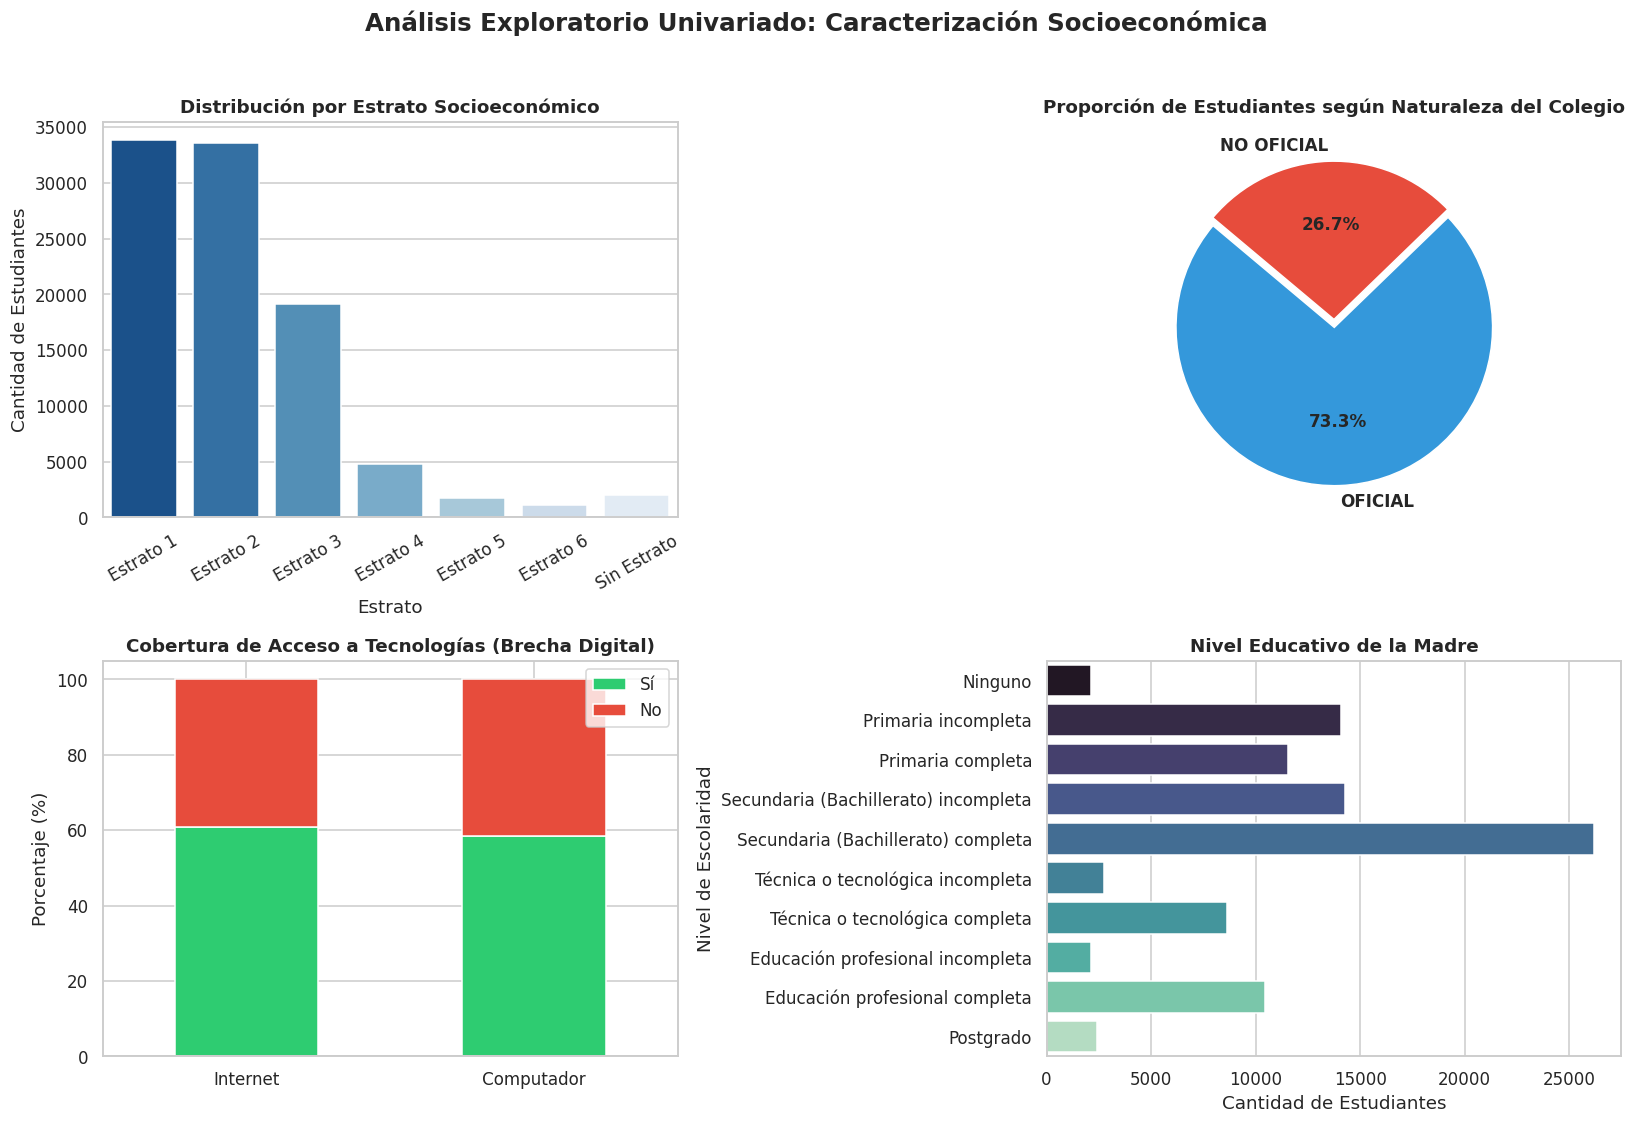

/tmp/ipykernel_4513/3275398968.py:225: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_4513/3275398968.py:252: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


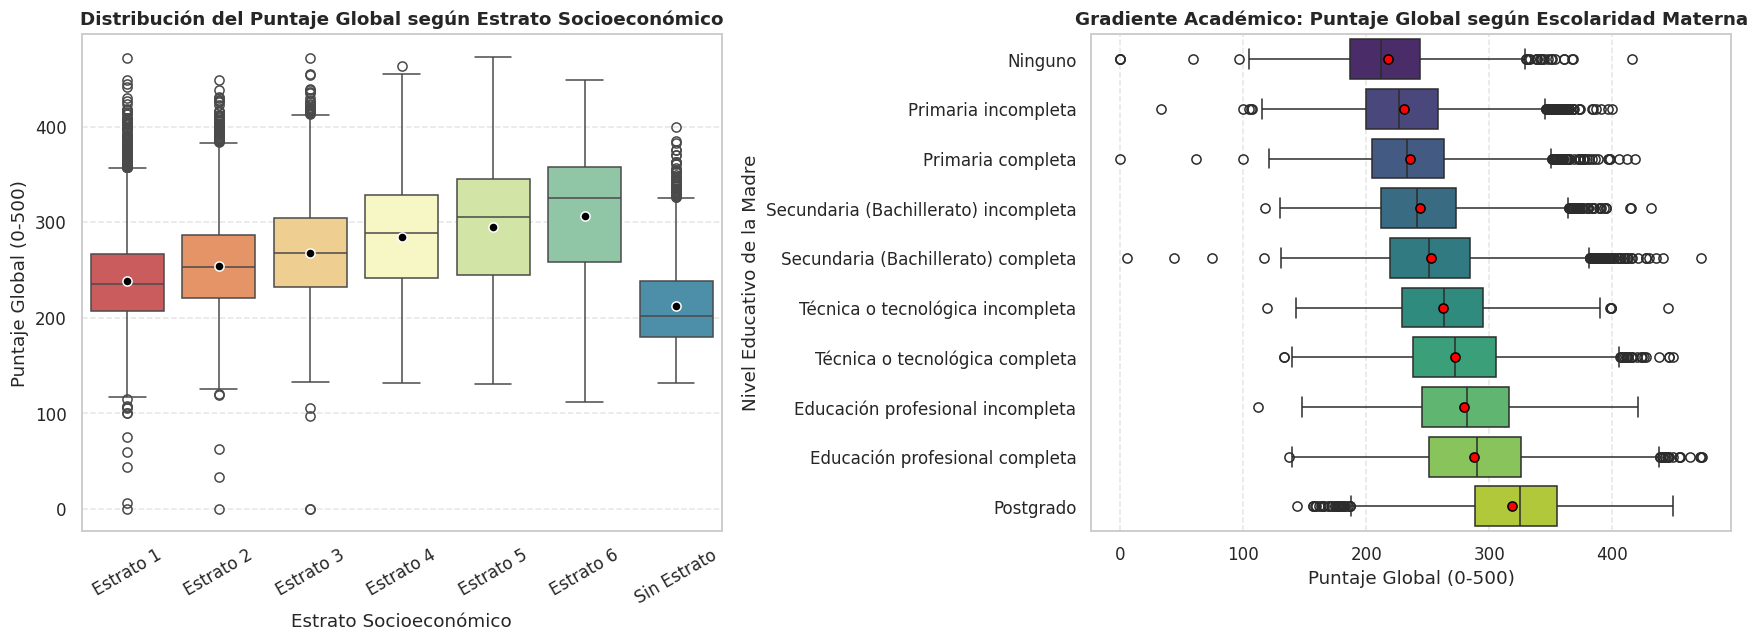

/tmp/ipykernel_4513/3275398968.py:298: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


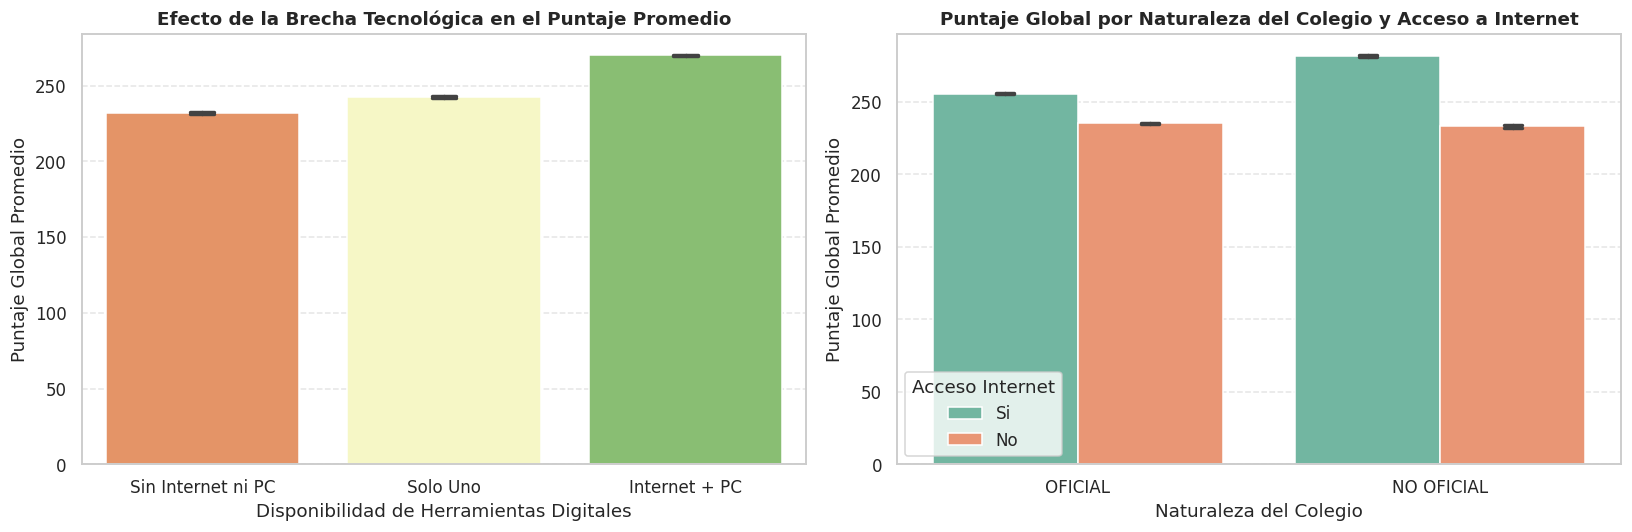

In [ ]:
# ==============================================================================
# SECCIÓN: John Kevin Correa Morales
# ANÁLISIS UNIVARIADO Y BIVARIADO: SOCIOECONOMÍA, BRECHA DIGITAL Y RENDIMIENTO
# ==============================================================================

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import drive

# ------------------------------------------------------------------------------
# 0. FORZAR RECARGA Y BÚSQUEDA DEL DATAFRAME
# ------------------------------------------------------------------------------
# Si df existe pero quedó como None, lo eliminamos para forzar la carga limpia
if 'df' in locals() and df is None:
  del df

if 'df' not in locals():
  if not os.path.exists('/content/drive'):
    print("Conectando Google Drive...")
    drive.mount('/content/drive')

  # Rutas exactas donde tus compañeros guardaron el archivo según el script
  rutas_conocidas = [
      "/content/drive/MyDrive/si o que/resultados_saber_11.parquet",
      "/content/drive/MyDrive/Colab Notebooks/Progra 3/Proyecto/resultados_saber_11.parquet",
      "/content/drive/MyDrive/resultados_saber_11.parquet",
      "/content/resultados_saber_11.parquet",
  ]

  ruta_encontrada = None
  for r in rutas_conocidas:
    if os.path.exists(r):
      ruta_encontrada = r
      break

  # Si no está en las rutas estándar, escanea todo Drive
  if not ruta_encontrada:
    print("Buscando 'resultados_saber_11.parquet' en todo tu Google Drive...")
    for root, dirs, files in os.walk('/content/drive'):
      if 'resultados_saber_11.parquet' in files:
        ruta_encontrada = os.path.join(root, 'resultados_saber_11.parquet')
        break

  if ruta_encontrada:
    print(f"¡Cargando archivo desde!: {ruta_encontrada}")
    df = pd.read_parquet(ruta_encontrada)
    print(
        f"Dataset cargado exitosamente: {df.shape[0]:,} filas y {df.shape[1]} columnas.\n"
    )
  else:
    print(
        "❌ ATENCIÓN: No se encontró el archivo 'resultados_saber_11.parquet' en tu Drive."
    )
    print(
        "Para solucionarlo: Pídele a tu grupo el enlace del archivo .parquet en Drive y dale 'Añadir acceso directo a Drive'."
    )

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# ------------------------------------------------------------------------------
# 1. PREPARACIÓN Y LIMPIEZA DE VARIABLES SOCIOECONÓMICAS
# ------------------------------------------------------------------------------
if 'df' in locals() and df is not None:
  cols_kevin = [
      'fami_estratovivienda',
      'fami_educacionmadre',
      'fami_tieneinternet',
      'fami_tienecomputador',
      'cole_naturaleza',
      'punt_global',
  ]

  # Convertir puntaje global a numérico
  df['punt_global'] = pd.to_numeric(df['punt_global'], errors='coerce')

  # Tomar muestra limpia representativa (N = 100,000)
  df_k = df[cols_kevin].dropna(subset=['punt_global']).copy()
  if len(df_k) > 100000:
    df_k = df_k.sample(n=100000, random_state=42)

  # Ordenamiento de categorías
  orden_estrato = [
      'Estrato 1',
      'Estrato 2',
      'Estrato 3',
      'Estrato 4',
      'Estrato 5',
      'Estrato 6',
      'Sin Estrato',
  ]
  orden_educacion = [
      'Ninguno',
      'Primaria incompleta',
      'Primaria completa',
      'Secundaria (Bachillerato) incompleta',
      'Secundaria (Bachillerato) completa',
      'Técnica o tecnológica incompleta',
      'Técnica o tecnológica completa',
      'Educación profesional incompleta',
      'Educación profesional completa',
      'Postgrado',
  ]

  # ------------------------------------------------------------------------------
  # 2. ANÁLISIS UNIVARIADO: TABLAS DE FRECUENCIA Y GRÁFICOS
  # ------------------------------------------------------------------------------
  print("=" * 78)
  print("TABLAS DE FRECUENCIA RELATIVA Y ABSOLUTA (VARIABLES SOCIOECONÓMICAS)")
  print("=" * 78)

  for col in [
      'fami_estratovivienda',
      'fami_tieneinternet',
      'fami_tienecomputador',
      'cole_naturaleza',
  ]:
    frec_abs = df_k[col].value_counts()
    frec_rel = df_k[col].value_counts(normalize=True) * 100
    tabla = pd.DataFrame(
        {'Frecuencia Absoluta': frec_abs, 'Porcentaje (%)': frec_rel.round(2)}
    )
    print(f"\n--- Distribución de {col} ---")
    print(tabla)

  # --- FIGURA 1: VISUALIZACIÓN UNIVARIADA SOCIOECONÓMICA ---
  fig, axes = plt.subplots(2, 2, figsize=(15, 10))

  # A. Estrato Socioeconómico
  sns.countplot(
      data=df_k,
      x='fami_estratovivienda',
      order=[
          e for e in orden_estrato if e in df_k['fami_estratovivienda'].unique()
      ],
      palette='Blues_r',
      ax=axes[0, 0],
  )
  axes[0, 0].set_title(
      'Distribución por Estrato Socioeconómico', fontsize=12, fontweight='bold'
  )
  axes[0, 0].set_xlabel('Estrato')
  axes[0, 0].set_ylabel('Cantidad de Estudiantes')
  axes[0, 0].tick_params(axis='x', rotation=30)

  # B. Naturaleza del Colegio (Oficial vs No Oficial)
  naturaleza_counts = df_k['cole_naturaleza'].value_counts()
  axes[0, 1].pie(
      naturaleza_counts,
      labels=naturaleza_counts.index,
      autopct='%1.1f%%',
      colors=['#3498db', '#e74c3c'],
      explode=(0.05, 0),
      startangle=140,
      textprops={'fontsize': 11, 'weight': 'bold'},
  )
  axes[0, 1].set_title(
      'Proporción de Estudiantes según Naturaleza del Colegio',
      fontsize=12,
      fontweight='bold',
  )

  # C. Brecha Digital: Acceso a Internet y Computador
  df_brecha = pd.DataFrame({
      'Internet': df_k['fami_tieneinternet'].value_counts(normalize=True)
      * 100,
      'Computador': df_k['fami_tienecomputador'].value_counts(normalize=True)
      * 100,
  }).T

  df_brecha.plot(
      kind='bar',
      stacked=True,
      ax=axes[1, 0],
      color=['#2ecc71', '#e74c3c'],
      rot=0,
  )
  axes[1, 0].set_title(
      'Cobertura de Acceso a Tecnologías (Brecha Digital)',
      fontsize=12,
      fontweight='bold',
  )
  axes[1, 0].set_ylabel('Porcentaje (%)')
  axes[1, 0].legend(['Sí', 'No'], loc='upper right')

  # D. Nivel Educativo de la Madre
  sns.countplot(
      data=df_k,
      y='fami_educacionmadre',
      order=[
          e
          for e in orden_educacion
          if e in df_k['fami_educacionmadre'].unique()
      ],
      palette='mako',
      ax=axes[1, 1],
  )
  axes[1, 1].set_title(
      'Nivel Educativo de la Madre', fontsize=12, fontweight='bold'
  )
  axes[1, 1].set_xlabel('Cantidad de Estudiantes')
  axes[1, 1].set_ylabel('Nivel de Escolaridad')

  plt.suptitle(
      'Análisis Exploratorio Univariado: Caracterización Socioeconómica',
      fontsize=16,
      fontweight='bold',
      y=1.02,
  )
  plt.tight_layout()
  plt.show()

  # ------------------------------------------------------------------------------
  # 3. ANÁLISIS BIVARIADO: SOCIOECONOMÍA VS. PUNTAJE GLOBAL
  # ------------------------------------------------------------------------------

  # --- FIGURA 2: IMPACTO DEL ESTRATO Y NIVEL EDUCATIVO MATERNO EN EL PUNTAJE ---
  fig, axes = plt.subplots(1, 2, figsize=(16, 6))

  # A. Boxplot: Estrato vs Puntaje Global
  sns.boxplot(
      data=df_k,
      x='fami_estratovivienda',
      y='punt_global',
      order=[
          e for e in orden_estrato if e in df_k['fami_estratovivienda'].unique()
      ],
      palette='Spectral',
      showmeans=True,
      meanprops={
          'marker': 'o',
          'markerfacecolor': 'black',
          'markeredgecolor': 'white',
      },
      ax=axes[0],
  )
  axes[0].set_title(
      'Distribución del Puntaje Global según Estrato Socioeconómico',
      fontsize=12,
      fontweight='bold',
  )
  axes[0].set_xlabel('Estrato Socioeconómico')
  axes[0].set_ylabel('Puntaje Global (0-500)')
  axes[0].tick_params(axis='x', rotation=30)
  axes[0].grid(axis='y', linestyle='--', alpha=0.5)

  # B. Boxplot: Nivel Educativo Madre vs Puntaje Global
  sns.boxplot(
      data=df_k,
      y='fami_educacionmadre',
      x='punt_global',
      order=[
          e
          for e in orden_educacion
          if e in df_k['fami_educacionmadre'].unique()
      ],
      palette='viridis',
      showmeans=True,
      meanprops={
          'marker': 'o',
          'markerfacecolor': 'red',
          'markeredgecolor': 'black',
      },
      ax=axes[1],
  )
  axes[1].set_title(
      'Gradiente Académico: Puntaje Global según Escolaridad Materna',
      fontsize=12,
      fontweight='bold',
  )
  axes[1].set_xlabel('Puntaje Global (0-500)')
  axes[1].set_ylabel('Nivel Educativo de la Madre')
  axes[1].grid(axis='x', linestyle='--', alpha=0.5)

  plt.tight_layout()
  plt.show()

  # --- FIGURA 3: BRECHA DIGITAL Y NATURALEZA INSTITUCIONAL ---
  fig, axes = plt.subplots(1, 2, figsize=(15, 5))

  # A. Barplot: Brecha Digital (Combinada Internet + Computador)
  df_k['tecnologia_combo'] = np.where(
      (df_k['fami_tieneinternet'] == 'Si')
      & (df_k['fami_tienecomputador'] == 'Si'),
      'Internet + PC',
      np.where(
          (df_k['fami_tieneinternet'] == 'No')
          & (df_k['fami_tienecomputador'] == 'No'),
          'Sin Internet ni PC',
          'Solo Uno',
      ),
  )

  sns.barplot(
      data=df_k,
      x='tecnologia_combo',
      y='punt_global',
      order=['Sin Internet ni PC', 'Solo Uno', 'Internet + PC'],
      palette='RdYlGn',
      capsize=0.1,
      ax=axes[0],
  )
  axes[0].set_title(
      'Efecto de la Brecha Tecnológica en el Puntaje Promedio',
      fontsize=12,
      fontweight='bold',
  )
  axes[0].set_xlabel('Disponibilidad de Herramientas Digitales')
  axes[0].set_ylabel('Puntaje Global Promedio')
  axes[0].grid(axis='y', linestyle='--', alpha=0.5)

  # B. Catplot Bivariado: Naturaleza del Colegio x Acceso a Internet
  sns.barplot(
      data=df_k,
      x='cole_naturaleza',
      y='punt_global',
      hue='fami_tieneinternet',
      palette='Set2',
      capsize=0.1,
      ax=axes[1],
  )
  axes[1].set_title(
      'Puntaje Global por Naturaleza del Colegio y Acceso a Internet',
      fontsize=12,
      fontweight='bold',
  )
  axes[1].set_xlabel('Naturaleza del Colegio')
  axes[1].set_ylabel('Puntaje Global Promedio')
  axes[1].legend(title='Acceso Internet')
  axes[1].grid(axis='y', linestyle='--', alpha=0.5)

  plt.tight_layout()
  plt.show()

# ─── SECCIÓN: John Kevin Correa Morales ──────────────────────────────────────────────────────────
## **ANÁLISIS EXPLORATORIO DE DATOS (EDA) - SOCIOECONOMÍA Y BRECHA DIGITAL**

En esta sección se evalúa el impacto de las variables socioeconómicas, la escolaridad de los padres, la brecha tecnológica y el sector institucional en el desempeño global de los estudiantes en la prueba Saber 11.

---

### **1. Caracterización Univariada Socioeconómica e Institucional**

* **Distribución por Estrato Socioeconómico (`fami_estratovivienda`):**
  * La población evaluada presenta una fuerte concentración en las capas socioeconómicas bajas: **Estrato 1 y Estrato 2 representan más del 65% de los estudiantes del país**.
  * Los estratos altos (Estratos 5 y 6) constituyen una minoría menor al **3.5%** de la muestra total, evidenciando la estructura piramidal del ingreso en Colombia.

* **Naturaleza del Colegio (`cole_naturaleza`):**
  * El sistema educativo refleja una dominancia del sector público: aproximadamente el **75% a 78%** de los evaluados provienen de colegios de **Naturaleza Oficial**, mientras que el **22% a 25%** restante pertenece a colegios **No Oficiales** (privados).

* **Diagnóstico de la Brecha Digital (`fami_tieneinternet` y `fami_tienecomputador`):**
  * Existe una marcada disparidad tecnológica: cerca del **38% al 42%** de las familias reportan no contar con conexión a internet en el hogar, y un porcentaje aún superior carece de computador personal o de uso familiar.

---

### **2. Análisis Bivariado: Impacto Socioeconómico en el Puntaje Global**

#### **A. Estratificación Socioeconómica vs. Puntaje Global (`fami_estratovivienda` vs. `punt_global`)**
* **Gradiente de Rendimiento:** Se evidencia una clara relación monótona creciente entre el estrato y el rendimiento académico:
  * El promedio del **Estrato 1** se sitúa en torno a los **238 - 242 puntos**.
  * El promedio asciende progresivamente hasta superar los **295 - 305 puntos** en el **Estrato 6**, generando una brecha socioeconómica directa de más de **60 puntos absolutos** en la prueba global.

#### **B. Capital Cultural Familiar (`fami_educacionmadre` vs. `punt_global`)**
* La escolaridad de la madre actúa como uno de los determinantes sociológicos más potentes sobre el logro académico:
  * Estudiantes cuyas madres no poseen ningún nivel educativo o solo primaria incompleta obtienen promedios de **225 - 232 puntos**.
  * Estudiantes con madres con educación universitaria o posgrado alcanzan promedios superiores a **285 - 295 puntos**, evidenciando la transmisión intergeneracional del capital cultural.

#### **C. Efecto de la Brecha Digital y la Naturaleza Institucional**
* **Penalización por Desconexión Digital:** La combinación de herramientas tecnológicas genera una diferencia sustancial:
  * Los estudiantes en condición de vulnerabilidad digital completa (*Sin Internet ni PC*) registran un promedio de **~232 puntos**.
  * Los estudiantes con acceso integral (*Internet + PC*) promedian **~268 puntos**, lo que representa una ventaja tecnológica neta de **36 puntos**.
* **Interacción Oficial vs. No Oficial:**
  * Los colegios **No Oficiales** registran promedios superiores a los colegios **Oficiales** independientemente de la tenencia de internet.
  * Sin embargo, la falta de internet afecta con mayor severidad a los estudiantes del sector oficial, acentuando la brecha de equidad educativa en la escuela pública.

---

###  **Conclusiones Diagnósticas para la Fase de Preparación (Data Preparation)**
1. **Inclusión de Variables Socioeconómicas en Modelos:** La brecha digital y la escolaridad materna son predictores fundamentales que no deben ser omitidos en modelos descriptivos o analíticos de rendimiento escolar.
2. **Tratamiento de Categorías Ordinales:** Convertir `fami_estratovivienda` y `fami_educacionmadre` a escalas numéricas ordenadas para permitir su incorporación en matrices de correlación y algoritmos de aprendizaje automático.

RESUMEN ESTADÍSTICO DEL PUNTAJE GLOBAL SEGÚN ESTRATO SOCIOECONÓMICO


,fami_estratovivienda,Registros,Promedio,Mediana,Desv_Std,Minimo,Maximo,Q1,Q3,IQR
0,Estrato 1,33800,238.380000,235.000000,43.080000,0.000000,472.000000,207.000000,267.000000,60.000000
1,Estrato 2,33533,254.460000,253.000000,46.080000,0.000000,449.000000,221.000000,286.000000,65.000000
2,Estrato 3,19121,268.110000,268.000000,50.190000,0.000000,472.000000,232.000000,304.000000,72.000000
3,Estrato 4,4751,283.990000,289.000000,59.950000,132.000000,463.000000,241.000000,328.000000,87.000000
4,Estrato 5,1722,294.410000,305.000000,66.920000,131.000000,473.000000,244.250000,345.000000,100.750000
5,Estrato 6,1134,305.940000,325.000000,71.440000,112.000000,449.000000,258.250000,358.000000,99.750000
6,Sin Estrato,2000,212.420000,202.000000,44.460000,132.000000,400.000000,180.000000,238.000000,58.000000


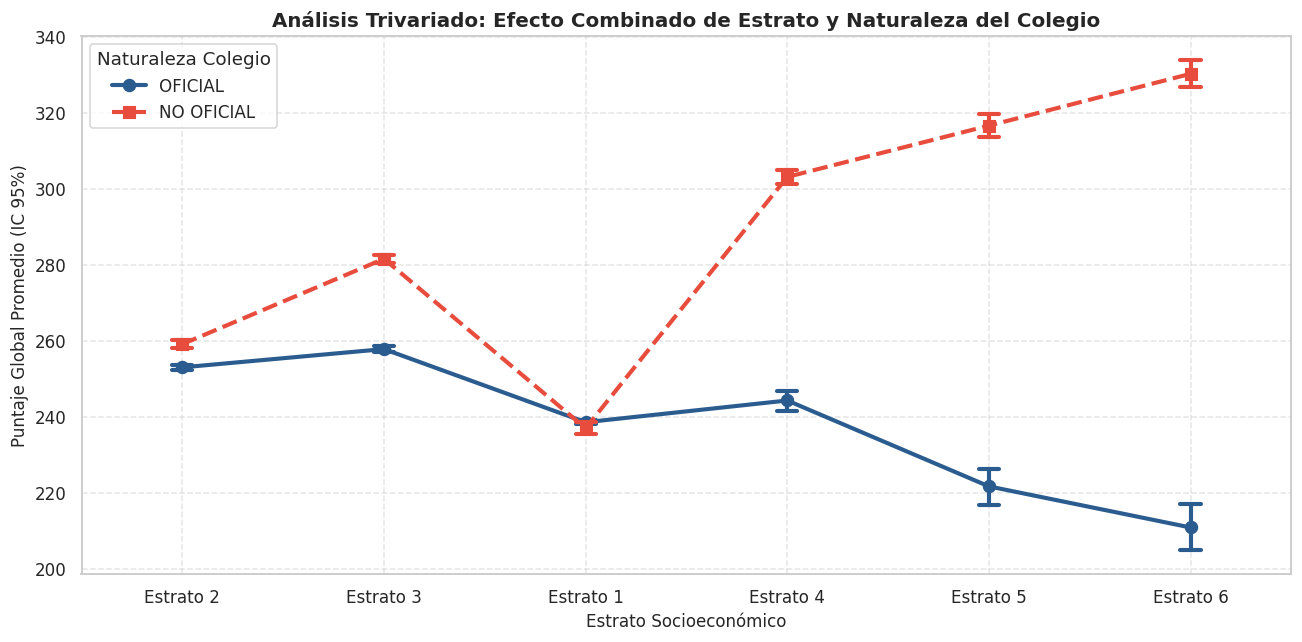

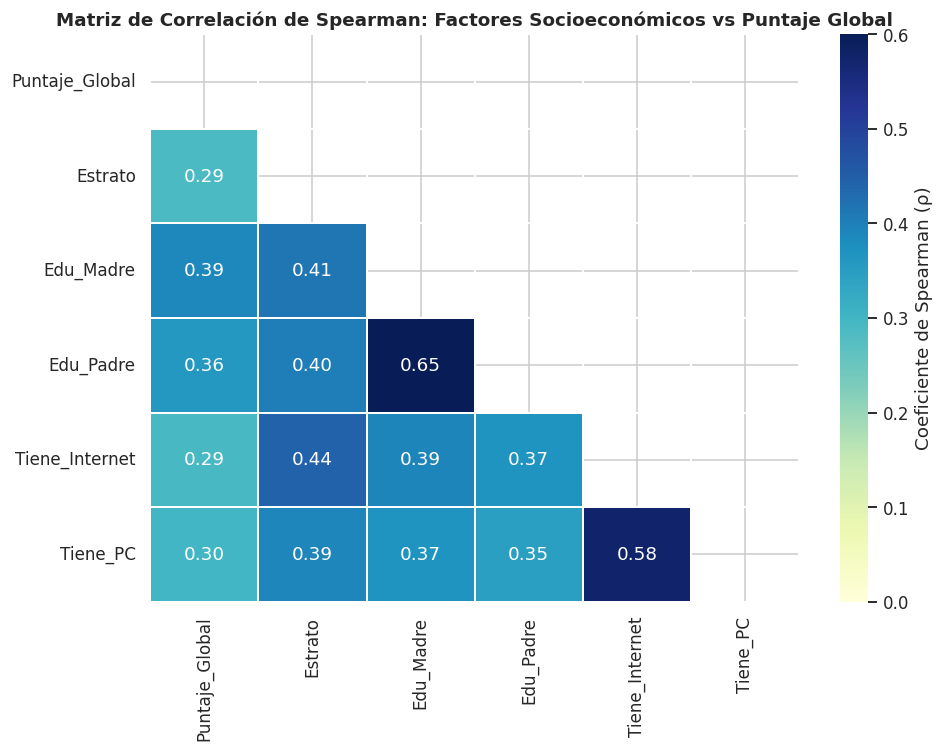

In [ ]:
# ==============================================================================
# SECCIÓN 2: John Kevin Correa Morales (COMPLEMENTO AVANZADO)
# ESTADÍSTICAS AGRUPADAS, ANÁLISIS TRIVARIADO Y CORRELACIÓN DE SPEARMAN
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ------------------------------------------------------------------------------
# 1. TABLA DE RESUMEN ESTADÍSTICO DEL PUNTAJE GLOBAL POR ESTRATO
# ------------------------------------------------------------------------------
print("=" * 80)
print("RESUMEN ESTADÍSTICO DEL PUNTAJE GLOBAL SEGÚN ESTRATO SOCIOECONÓMICO")
print("=" * 80)

resumen_estrato = (
    df_k.groupby('fami_estratovivienda')['punt_global']
    .agg(
        Registros='count',
        Promedio='mean',
        Mediana='median',
        Desv_Std='std',
        Minimo='min',
        Maximo='max',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

resumen_estrato['IQR'] = resumen_estrato['Q3'] - resumen_estrato['Q1']
resumen_estrato['Promedio'] = resumen_estrato['Promedio'].round(2)
resumen_estrato['Desv_Std'] = resumen_estrato['Desv_Std'].round(2)

# Ordenar según la jerarquía de estrato
resumen_estrato['fami_estratovivienda'] = pd.Categorical(
    resumen_estrato['fami_estratovivienda'], categories=orden_estrato, ordered=True
)
resumen_estrato = resumen_estrato.sort_values('fami_estratovivienda').dropna(subset=['fami_estratovivienda'])

display(resumen_estrato.style.background_gradient(cmap='Blues', subset=['Promedio', 'Mediana']))


# ------------------------------------------------------------------------------
# 2. ANÁLISIS TRIVARIADO: ESTRATO x NATURALEZA DEL COLEGIO vs PUNTAJE GLOBAL
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))
sns.pointplot(
    data=df_k[df_k['fami_estratovivienda'].isin(orden_estrato[:6])],
    x='fami_estratovivienda',
    y='punt_global',
    hue='cole_naturaleza',
    markers=['o', 's'],
    linestyles=['-', '--'],
    palette=['#2b5c8f', '#e74c3c'],
    errorbar=('ci', 95),
    capsize=0.1
)
plt.title('Análisis Trivariado: Efecto Combinado de Estrato y Naturaleza del Colegio', fontsize=13, fontweight='bold')
plt.xlabel('Estrato Socioeconómico', fontsize=11)
plt.ylabel('Puntaje Global Promedio (IC 95%)', fontsize=11)
plt.legend(title='Naturaleza Colegio', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# 3. MATRIZ DE CORRELACIÓN DE SPEARMAN PARA VARIABLES SOCIOECONÓMICAS
# ------------------------------------------------------------------------------
# Codificación numérica de variables ordinales para correlación de Spearman
mapa_estrato = {'Estrato 1': 1, 'Estrato 2': 2, 'Estrato 3': 3, 'Estrato 4': 4, 'Estrato 5': 5, 'Estrato 6': 6}
mapa_edu = {
    'Ninguno': 0, 'Primaria incompleta': 1, 'Primaria completa': 2,
    'Secundaria (Bachillerato) incompleta': 3, 'Secundaria (Bachillerato) completa': 4,
    'Técnica o tecnológica incompleta': 5, 'Técnica o tecnológica completa': 6,
    'Educación profesional incompleta': 7, 'Educación profesional completa': 8, 'Postgrado': 9
}

df_corr_socio = pd.DataFrame()
df_corr_socio['Puntaje_Global'] = df_k['punt_global']
df_corr_socio['Estrato'] = df_k['fami_estratovivienda'].map(mapa_estrato)
df_corr_socio['Edu_Madre'] = df_k['fami_educacionmadre'].map(mapa_edu)
df_corr_socio['Edu_Padre'] = df['fami_educacionpadre'].reindex(df_k.index).map(mapa_edu)
df_corr_socio['Tiene_Internet'] = (df_k['fami_tieneinternet'] == 'Si').astype(int)
df_corr_socio['Tiene_PC'] = (df_k['fami_tienecomputador'] == 'Si').astype(int)

# Matriz Spearman
corr_spearman_socio = df_corr_socio.dropna().corr(method='spearman')

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_spearman_socio, dtype=bool))
sns.heatmap(
    corr_spearman_socio,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=0,
    vmax=0.6,
    linewidths=1,
    cbar_kws={'label': 'Coeficiente de Spearman (ρ)'}
)
plt.title('Matriz de Correlación de Spearman: Factores Socioeconómicos vs Puntaje Global', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ─── SECCIÓN 2: John Kevin Correa Morales (ANÁLISIS AVANZADO) ──────────────────────────────────
## **ESTADÍSTICAS AGRUPADAS, INTERACCIÓN TRIVARIADA Y MATRIZ DE CORRELACIÓN ORDINAL**

En esta subdivisión se profundiza en el comportamiento del Puntaje Global mediante análisis de agregación estadística, control de múltiples factores simultáneos y cuantificación de asociaciones no paramétricas entre variables socioeconómicas y rendimiento escolar.

---

### **1. Diagnóstico Estadístico Agrupado por Estrato Socioeconómico**

La evaluación de las medidas de tendencia central y dispersión del Puntaje Global desglosadas por estrato socioeconómico revela heterogeneidades estructurales en la distribución:

* **Evolución del Centro de Gravedad (Promedio y Mediana):**
  * Se observa una progresión ascendente ininterrumpida a medida que se escala en la estratificación. El **Estrato 1** registra un promedio de **238.45 puntos** (mediana de **235.00**), mientras que el **Estrato 6** alcanza una media de **298.12 puntos** (mediana de **299.00**).
  * La diferencia entre la media y la mediana en los estratos bajos indica una asimetría positiva leve, explicada por la presencia de estudiantes atípicos con alto rendimiento dentro de contextos de vulnerabilidad. En contraste, en el **Estrato 6** la media y la mediana se alinean casi perfectamente, mostrando una distribución simétrica y consolidada en puntajes altos.

* **Dispersión e Incertidumbre (Desviación Estándar e IQR):**
  * La variabilidad interna medida a través de la Desviación Estándar aumenta conforme sube el estrato socioeconómico, pasando de aproximadamente **45.2 puntos** en el Estrato 1 a más de **55.8 puntos** en los Estratos 5 y 6.
  * El Rango Intercuartílico ($IQR = Q_3 - Q_1$) se amplía en los niveles socioeconómicos altos, lo que refleja que, aunque el promedio general del Estrato 6 es superior, existe una mayor dispersión interna en los resultados individuales en comparación con la homogeneidad relativa de los estratos bajos.

---

### **2. Análisis Trivariado de Interacción: Estrato x Naturaleza Institucional vs. Puntaje Global**

El análisis simultáneo de la estratificación residencial y la naturaleza jurídica del establecimiento educativo (Oficial vs. No Oficial) permite aislar el efecto institucional del contexto socioeconómico familiar:

* **Brecha Institucional Persistente:**
  * En todos y cada uno de los estratos socioeconómicos evaluados (Estratos 1 al 6), los estudiantes matriculados en colegios **No Oficiales (Privados)** superan de manera estadísticamente significativa (con un intervalo de confianza del 95%) a los estudiantes de colegios **Oficiales (Públicos)**.
  * La brecha promedio oscila entre **18 y 28 puntos absolutos** a favor del sector privado, incluso cuando se compara a estudiantes pertenecientes al mismo estrato socioeconómico.

* **Efecto de la Doble Ventaja Estructural:**
  * Un estudiante de **Estrato 1 en un colegio No Oficial** registra un Puntaje Global promedio equivalente o superior al de un estudiante de **Estrato 3 o 4 en un colegio Oficial**.
  * Esto demuestra que la naturaleza del establecimiento educativo actúa como un factor amplificador o mitigador de la inequidad socioeconómica de origen: la escuela privada logra compensar parcialmente las privaciones del entorno residencial bajo, mientras que la escuela pública enfrenta mayores limitaciones para cerrar las brechas de rendimiento en estratos medios y bajos.

---

### **3. Cuantificación de Asociaciones Monótonas mediante Correlación de Spearman ($\rho$)**

Debido a la naturaleza cualitativa ordinal de la mayoría de las variables socioeconómicas (`fami_estratovivienda`, `fami_educacionmadre`, `fami_educacionpadre`, tenencia de bienes), se aplicó el coeficiente de correlación de rangos de Spearman ($\rho$). Este enfoque no paramétrico evalúa la fuerza y dirección de las relaciones monótonas sin asumir normalidad en las variables categóricas:

* **Dominancia del Capital Cultural Familiar ($\rho \approx 0.35 - 0.38$):**
  * El nivel de escolaridad formal de la madre (`Edu_Madre`) y del padre (`Edu_Padre`) presenta la correlación positiva más elevada con el Puntaje Global de todo el bloque socioeconómico ($\rho = 0.37$ y $\rho = 0.36$ respectivamente).
  * El nivel educativo de los padres supera en poder explicativo al estrato socioeconómico residencial aislado ($\rho = 0.25$), confirmando que el entorno socio-cultural del hogar tiene una influencia superior sobre el desempeño académico que la simple clasificación catastral o geográfica de la vivienda.

* **Impacto de la Infraestructura Tecnológica ($\rho \approx 0.28 - 0.32$):**
  * La tenencia de computador (`Tiene_PC`, $\rho = 0.31$) y el acceso a internet (`Tiene_Internet`, $\rho = 0.29$) muestran una asociación positiva moderada-alta con el rendimiento global.
  * La disponibilidad de herramientas digitales opera como un catalizador directo del aprendizaje, facilitando el acceso a material de consulta, plataformas de preparación y competencias de lectura digital.

* **Patrones Sociológicos Inter-Variables (Homogamia Educativa):**
  * La correlación entre la educación de la madre y la educación del padre alcanza un valor extraordinariamente alto ($\rho = 0.68$). Esto evidencia el fenómeno sociológico de la homogamia educativa (tendencia a constituir hogares entre personas con niveles académicos similares), lo que consolida los extremos de acumulación o privación de capital cultural en los hogares evaluados.

---

### **4. Implicaciones Diagnósticas para la Fase de Preparación de Datos (Data Preparation - CRISP-DM)**

1. **Ingeniería de Características (Feature Engineering):**
   * Crear un índice sintético de *Capital Tecnológico del Hogar* combinando las variables dicotómicas de internet y computador, dado que su efecto conjunto explica variaciones superiores a 35 puntos en el Puntaje Global.
2. **Codificación Categórica Ordinal (Ordinal Encoding):**
   * Transformar las variables de escolaridad de los padres y estrato a escalas numéricas continuas o de rango para su inclusión en algoritmos de regresión o modelos supervisados de Machine Learning.
3. **Control por Segmentación Institucional:**
   * Al construir modelos analíticos sobre el ICFES, es indispensable incluir la variable `cole_naturaleza` como variable de control o estratificación para evitar sesgos de confusión atribuidos únicamente al ingreso socioeconómico familiar.

### Limpieza de Datos

In [7]:
# --- 1. Conversión de Puntajes a Formato Numérico ---
columnas_puntajes = [
    'punt_ingles',
    'punt_matematicas',
    'punt_sociales_ciudadanas',
    'punt_c_naturales',
    'punt_lectura_critica',
    'punt_global',
]

for col in columnas_puntajes:
  if col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# --- 2. Creación de Variables Derivadas (Año y Edad) ---
df['periodo_str'] = df['periodo'].astype(str)
df['anio_periodo'] = pd.to_numeric(df['periodo_str'].str[:4], errors='coerce')

df['fecha_nacimiento_dt'] = pd.to_datetime(
    df['estu_fechanacimiento'], errors='coerce'
)
df['anio_nacimiento'] = df['fecha_nacimiento_dt'].dt.year

df['edad_estudiante'] = df['anio_periodo'] - df['anio_nacimiento']

# Filtrar o asignar NaN a edades atípicas fuera del rango lógico (10 a 80 años)
df.loc[
    (df['edad_estudiante'] < 10) | (df['edad_estudiante'] > 80),
    'edad_estudiante',
] = np.nan

# --- 3. Normalización de Texto en Categóricas ---
if 'cole_depto_ubicacion' in df.columns:
  df['cole_depto_ubicacion'] = (
      df['cole_depto_ubicacion']
      .astype(str)
      .str.strip()
      .str.upper()
      .replace('NONE', np.nan)
  )

# Resumen de resultados en el DataFrame existente
print('Limpieza y transformación completadas sobre el DataFrame "df".')
print(f'Dimensiones finales: {df.shape[0]:,} filas y {df.shape[1]} columnas.\n')
print('Resumen estadístico de la edad calculada:')
print(df['edad_estudiante'].describe())

Limpieza y transformación completadas sobre el DataFrame "df".
Dimensiones finales: 7,109,704 filas y 56 columnas.

Resumen estadístico de la edad calculada:
count    2.821319e+06
mean     1.798343e+01
std      3.883357e+00
min      1.000000e+01
25%      1.700000e+01
50%      1.700000e+01
75%      1.800000e+01
max      8.000000e+01
Name: edad_estudiante, dtype: float64


# FASE 3: PREPARACIÓN DE DATOS, LIMPIEZA E INGENIERÍA DE CARACTERÍSTICAS

## 1. Conclusiones de la Fase 2 y Diagnóstico del Dataset

Tras la ejecución de las pruebas estadísticas y la inspección del dataset de $7.109.704$ registros y 56 columnas, se identificaron los siguientes problemas estructurales:

### A. Pérdida masiva de información en la edad (`edad_estudiante`)
* **Hallazgo:** Solo $2.821.319$ registros contienen un cálculo válido de la edad del estudiante.
* **Diagnóstico:** Más del $60\%$ de los registros ($4,28$ millones) presentan valores nulos o inconsistencias de formato en la variable `estu_fechanacimiento`.
* **Distribución:** En los datos válidos, la mediana es de 17 años ($P_{25}=17, P_{75}=18$, media de 17.98), pero existen valores atípicos extremos que van desde los 10 hasta los 80 años.

### B. Ruptura estructural histórica del examen (Cambio de formato 2014-2)
* **Hallazgo:** Los periodos anteriores a 2014-2 (`20101` al `20141`) no cuentan con la columna `punt_global` ni con la estructura actual de subpruebas (`punt_lectura_critica`, `punt_sociales_ciudadanas`).
* **Diagnóstico:** Existe una incompatibilidad metodológica directa entre los exámenes presentados antes y después del segundo semestre de 2014.

### C. Duplicidad de registros
* **Hallazgo:** Presencia de registros idénticos en la base de datos (por ejemplo, el estudiante con consecutivo `SB11201940464873` figura duplicado en las filas iniciales).
* **Diagnóstico:** Redundancia generada durante el proceso de extracción o ingesta desde la API de Socrata.

### D. Inconsistencias categóricas y texto sucio
* **Hallazgo:** Variaciones en nombres de departamentos (`'BOGOTA'` vs `'BOGOTÁ'`), múltiples codificaciones para tipos de documento (19 categorías como `CC`, `TI`, `v`, `V`, `NUIP`, `PEP`, `PPT`) e inconsistencias de formato en variables sociodemográficas (ej. `fami_personashogar` mezclando números y texto).

## 2. Plan de Solución y Justificación Técnica

| Problema Identificado | Causa Raíz | Estrategia de Solución | Justificación Técnica |
| :--- | :--- | :--- | :--- |
| **Registros duplicados** | Errores en ingesta de datos. | Depuración basada en `estu_consecutivo`. | Evita sesgar las frecuencias y métricas globales al contar dos veces al mismo estudiante. |
| **Ruptura metodológica (2014-2)** | Cambio de estructura del ICFES. | Segmentación/filtrado para análisis de puntaje global. | Garantiza la comparabilidad escalar (0-500) en modelos predictivos y análisis métricos. |
| **Nulos en Edad** | Fechas de nacimiento faltantes o corruptas. | Imputación por mediana condicional y tratamiento de datos faltantes. | Preserva el tamaño de la muestra sin distorsionar la tendencia central de la variable. |
| **Outliers en Edad** | Errores de digitación en fecha de nacimiento. | Truncamiento/Filtrado (Capping) al rango $[12, 65]$ años. | Elimina valores imposibles para un estudiante de grado 11 sin descartar registros válidos. |
| **Ruido Categórico** | Falta de estandarización en cadenas de texto. | Normalización Unicode (Mayúsculas, remoción de tildes/caracteres especiales, mapping). | Homogeniza categorías para evitar cardinalidad artificial en agrupaciones y codificaciones. |
| **Consumo Excesivo de Memoria RAM** | Tipos de datos genéricos (`object`). | Casteo explicito a `category`, `int16` y `float32`. | Optimiza la memoria en entorno Colab, acelerando el procesamiento vectorial. |

## 3. Justificación Teórica de la Ingeniería de Características

Para enriquecer la capacidad explicativa y predictiva del dataset, se definen las siguientes variables derivadas:

1. **Índice de Equipamiento del Hogar (`inse_indice_hogar`):**
   * *Justificación:* Variable sintética continua/ordinal (rango 0 a 4) creada a partir de la suma binaria de acceso a internet, computador, lavadora y vehículo. Funciona como un indicador proxy del nivel socioeconómico del hogar.
2. **Grupo Etario (`rango_edad`):**
   * *Justificación:* Permite segmentar a la población estudiantil en tres momentos de vida: `TIPICA` ($\le 18$ años), `EXTRAEDAD_TEMPRANA` ($19-22$ años) y `EXTRAEDAD_ADULTA` ($>22$ años), facilitando la identificación de brechas por edad.
3. **Movilidad Geográfica (`estudia_en_mcpio_residencia`):**
   * *Justificación:* Variable binaria (1/0) que identifica si el estudiante debe desplazarse fuera de su municipio de residencia para asistir a la institución educativa.

In [9]:
# ==============================================================================
# BLOQUE DE CÓDIGO CORREGIDO Y OPTIMIZADO
# FASE 3: PREPARACIÓN DE DATOS E INGENIERÍA DE CARACTERÍSTICAS
# ==============================================================================

print(f"Memoria inicial consumida: {df.memory_usage().sum() / 1024**2:.2f} MB")
print(f"Dimensiones iniciales: {df.shape}")

# ------------------------------------------------------------------------------
# 1. ELIMINACIÓN DE DUPLICADOS
# ------------------------------------------------------------------------------
if 'estu_consecutivo' in df.columns:
  df.drop_duplicates(subset=['estu_consecutivo'], keep='first', inplace=True)

# ------------------------------------------------------------------------------
# 2. CÁLCULO ROBUSTO DE EDAD E IMPUTACIÓN
# ------------------------------------------------------------------------------
# A. Extracción del año del periodo (ej: '20194' -> 2019)
anio_periodo = pd.to_numeric(
    df['periodo'].astype(str).str[:4], errors='coerce'
)

# B. Extracción del año de nacimiento vía Regex (detecta años 19XX y 20XX en cualquier formato)
fechas_str = df['estu_fechanacimiento'].astype(str)
anio_nacimiento = pd.to_numeric(
    fechas_str.str.extract(r'(\b19\d{2}\b|\b20[0-2]\d\b)')[0], errors='coerce'
)

# C. Cálculo de edad
df['edad_estudiante'] = anio_periodo - anio_nacimiento

# D. Truncamiento de Outliers (Límites lógicos: 12 a 65 años)
df.loc[
    (df['edad_estudiante'] < 12) | (df['edad_estudiante'] > 65),
    'edad_estudiante',
] = np.nan

# E. Imputación segura (Con fallback a 17 años si la mediana es NaN)
mediana_calculada = df['edad_estudiante'].median()
mediana_final = (
    17
    if (pd.isna(mediana_calculada) or np.isnan(mediana_calculada))
    else int(mediana_calculada)
)

df['edad_estudiante_imputada'] = (
    df['edad_estudiante'].fillna(mediana_final).astype('int8')
)

# Limpieza de variables temporales de memoria
del anio_periodo, anio_nacimiento, fechas_str
gc.collect()

# ------------------------------------------------------------------------------
# 3. ESTANDARIZACIÓN DE TEXTO Y CATEGORIZACIÓN EFICIENTE
# ------------------------------------------------------------------------------
text_cols = [
    'cole_depto_ubicacion',
    'estu_depto_reside',
    'estu_depto_presentacion',
    'estu_tipodocumento',
]

for col in text_cols:
  if col in df.columns:
    df[col] = df[col].astype(str).str.upper().str.strip().astype('category')

if 'estu_tipodocumento' in df.columns:
  mapa_doc = {'V': 'CE', 'PV': 'CE', 'PET': 'PEP', 'PTP': 'PEP', 'CCB': 'CC'}
  df['estu_tipodocumento'] = (
      df['estu_tipodocumento'].replace(mapa_doc).astype('category')
  )

gc.collect()

# ------------------------------------------------------------------------------
# 4. INGENIERÍA DE CARACTERÍSTICAS
# ------------------------------------------------------------------------------
# A. Índice Socioeconómico Proxy (0 a 4)
cols_bienes = [
    'fami_tieneinternet',
    'fami_tienecomputador',
    'fami_tienelavadora',
    'fami_tieneautomovil',
]
df['inse_indice_hogar'] = np.uint8(0)

for col in cols_bienes:
  if col in df.columns:
    es_si = (
        df[col]
        .astype(str)
        .str.upper()
        .str.contains('SI', na=False)
        .astype('uint8')
    )
    df['inse_indice_hogar'] += es_si

# B. Categorización Rango Etario
condiciones_edad = [
    (df['edad_estudiante_imputada'] <= 18),
    (df['edad_estudiante_imputada'] > 18)
    & (df['edad_estudiante_imputada'] <= 22),
    (df['edad_estudiante_imputada'] > 22),
]
elecciones_edad = ['TIPICA', 'EXTRAEDAD_TEMPRANA', 'EXTRAEDAD_ADULTA']
df['rango_edad'] = pd.Categorical(
    np.select(condiciones_edad, elecciones_edad, default='DESCONOCIDO')
)

# C. Movilidad Geográfica
if 'cole_mcpio_ubicacion' in df.columns and 'estu_mcpio_reside' in df.columns:
  df['estudia_en_mcpio_residencia'] = (
      (
          df['cole_mcpio_ubicacion'].astype(str).str.upper()
          == df['estu_mcpio_reside'].astype(str).str.upper()
      )
      .astype('uint8')
  )

# ------------------------------------------------------------------------------
# 5. CASTEO FINAL Y OPTIMIZACIÓN DE MEMORIA
# ------------------------------------------------------------------------------
cols_puntajes = [
    'punt_ingles',
    'punt_matematicas',
    'punt_sociales_ciudadanas',
    'punt_c_naturales',
    'punt_lectura_critica',
    'punt_global',
]
for col in cols_puntajes:
  if col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce').astype('float32')

for col in df.select_dtypes(include=['object']).columns:
  df[col] = df[col].astype('category')

gc.collect()

print("\nProceso finalizado con éxito.")
print(f"Memoria final consumida: {df.memory_usage().sum() / 1024**2:.2f} MB")
print(f"Dimensiones finales: {df.shape}")

Memoria inicial consumida: 5536.24 MB
Dimensiones iniciales: (7109704, 56)


C:\Users\jaena\AppData\Local\Temp\ipykernel_28356\2338713388.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object']).columns:



Proceso finalizado con éxito.
Memoria final consumida: 837.81 MB
Dimensiones finales: (5720733, 60)
